In [ ]:

from pathlib import Path
from collections import Counter
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

# --------------------------------------------------
# 1. SOURCE AND OUTPUT PATHS
# --------------------------------------------------
train_dir = Path(
    "/kaggle/input/datasets/riyaelizashaju/"
    "skin-disease-classification-image-dataset/"
    "Split_smol/train"
)

val_dir = Path(
    "/kaggle/input/datasets/riyaelizashaju/"
    "skin-disease-classification-image-dataset/"
    "Split_smol/val"
)

merged_dir = Path("/kaggle/working/merged_skin_dataset")

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"
}

assert train_dir.exists(), f"Train folder not found: {train_dir}"
assert val_dir.exists(), f"Validation folder not found: {val_dir}"

# --------------------------------------------------
# 2. MERGE TRAIN + VAL INTO ONE CLASS-WISE DATASET
# --------------------------------------------------
if merged_dir.exists():
    shutil.rmtree(merged_dir)

merged_dir.mkdir(parents=True, exist_ok=True)

source_dirs = [
    ("train", train_dir),
    ("val", val_dir)
]

copied_counts = Counter()
skipped_counts = Counter()

for split_name, source_dir in source_dirs:
    for class_dir in sorted(source_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        class_name = class_dir.name
        destination_class = merged_dir / class_name
        destination_class.mkdir(parents=True, exist_ok=True)

        image_paths = sorted(
            p for p in class_dir.rglob("*")
            if p.is_file()
            and p.suffix.lower() in IMAGE_EXTENSIONS
        )

        for index, src in enumerate(image_paths):
            new_name = f"{split_name}_{index:06d}_{src.name}"
            destination = destination_class / new_name

            try:
                with Image.open(src) as img:
                    img.verify()

                shutil.copy2(src, destination)
                copied_counts[class_name] += 1

            except Exception as e:
                skipped_counts[class_name] += 1
                print(f"Skipped invalid image: {src} | {e}")

print("=" * 60)
print("MERGE COMPLETED")
print("=" * 60)
print("Merged dataset path:", merged_dir)
print("Number of classes:", len(copied_counts))
print("Total valid images:", sum(copied_counts.values()))
print("Invalid images skipped:", sum(skipped_counts.values()))

# --------------------------------------------------
# 3. NUMBER OF SAMPLES IN EACH CLASS
# --------------------------------------------------
class_names = sorted(
    p.name for p in merged_dir.iterdir() if p.is_dir()
)

class_counts = []

for class_name in class_names:
    class_path = merged_dir / class_name

    images = [
        p for p in class_path.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    class_counts.append({
        "Class": class_name,
        "Number of Samples": len(images)
    })

counts_df = pd.DataFrame(class_counts)

print("\nSAMPLES IN EACH CLASS")
display(counts_df)

print("\nTotal classes:", len(counts_df))
print("Total samples:", counts_df["Number of Samples"].sum())

# --------------------------------------------------
# 4. STANDARDIZED VISUALIZATION
#    Show ONLY class names above images.
#    No sample counts in image titles.
# --------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

n_classes = len(class_names)
ncols = 3
nrows = (n_classes + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(15, 4.8 * nrows),
    dpi=150,
    squeeze=False
)

fig.suptitle(
    "Skin Disease Dataset — One Sample per Class",
    fontsize=17,
    fontweight="bold",
    y=0.995
)

for ax, class_name in zip(axes.flat, class_names):
    class_path = merged_dir / class_name

    image_paths = sorted(
        p for p in class_path.iterdir()
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    ax.axis("off")

    if not image_paths:
        ax.set_title(
            class_name,
            fontsize=13,
            fontweight="bold",
            pad=10
        )
        continue

    # One deterministic sample per class
    sample_path = image_paths[0]

    try:
        with Image.open(sample_path) as img:
            image = img.convert("RGB")

        ax.imshow(image)

        # Class name ONLY — no sample count
        ax.set_title(
            class_name,
            fontsize=13,
            fontweight="bold",
            pad=10,
            wrap=True
        )

    except Exception as e:
        ax.set_title(
            class_name,
            fontsize=13,
            fontweight="bold",
            pad=10
        )
        print(f"Display error: {sample_path} | {e}")

# Hide unused grid cells
for ax in axes.flat[n_classes:]:
    ax.axis("off")

plt.tight_layout(
    rect=[0, 0, 1, 0.975],
    h_pad=2.0,
    w_pad=1.5
)
plt.show()

# --------------------------------------------------
# 5. CLASS DISTRIBUTION BAR CHART
#    Sample counts remain here, not on image titles.
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 6), dpi=150)

ax.bar(
    counts_df["Class"],
    counts_df["Number of Samples"]
)

ax.set_title(
    "Merged Dataset — Class Distribution",
    fontsize=16,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("Disease Class", fontsize=12)
ax.set_ylabel("Number of Images", fontsize=12)

ax.tick_params(axis="x", labelrotation=35, labelsize=10)
ax.tick_params(axis="y", labelsize=10)

for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:

from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd

source_dirs = {
    "train": Path(
        "/kaggle/input/datasets/riyaelizashaju/"
        "skin-disease-classification-image-dataset/"
        "Split_smol/train"
    ),
    "val": Path(
        "/kaggle/input/datasets/riyaelizashaju/"
        "skin-disease-classification-image-dataset/"
        "Split_smol/val"
    )
}

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

hash_groups = defaultdict(list)

for split, root in source_dirs.items():
    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in extensions:
            try:
                digest = sha256_file(path)
                class_name = path.parent.name
                hash_groups[digest].append({
                    "split": split,
                    "class": class_name,
                    "path": str(path)
                })
            except Exception as e:
                print("Could not read:", path, e)

duplicates = []

for digest, files in hash_groups.items():
    if len(files) > 1:
        for item in files:
            duplicates.append({
                "SHA256": digest,
                "Split": item["split"],
                "Class": item["class"],
                "Path": item["path"],
                "Copies in group": len(files)
            })

duplicate_df = pd.DataFrame(duplicates)

print("Total image files scanned:", sum(map(len, hash_groups.values())))
print("Unique file contents:", len(hash_groups))
print("Duplicate groups:", sum(
    1 for files in hash_groups.values() if len(files) > 1
))
print("Files belonging to duplicate groups:", len(duplicate_df))

if not duplicate_df.empty:
    display(duplicate_df.sort_values(["SHA256", "Split"]))
    duplicate_df.to_csv(
        "/kaggle/working/exact_duplicates.csv", index=False
    )
    print("Report saved to /kaggle/working/exact_duplicates.csv")
else:
    print("No exact duplicate files found.")

In [ ]:

from pathlib import Path
from collections import defaultdict, Counter
import hashlib
import random
import shutil
import pandas as pd
from PIL import Image

# ==================================================
# 1. PATHS AND SETTINGS
# ==================================================
SEED = 123

source_dirs = [
    Path("/kaggle/input/datasets/riyaelizashaju/"
         "skin-disease-classification-image-dataset/"
         "Split_smol/train"),
    Path("/kaggle/input/datasets/riyaelizashaju/"
         "skin-disease-classification-image-dataset/"
         "Split_smol/val")
]

output_dir = Path("/kaggle/working/skin_clean_split")

extensions = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

random.seed(SEED)

# ==================================================
# 2. SCAN IMAGES AND COMPUTE EXACT HASHES
# ==================================================
hash_groups = defaultdict(list)
bad_files = []

for root in source_dirs:
    if not root.exists():
        raise FileNotFoundError(f"Folder not found: {root}")

    for path in sorted(root.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in extensions:
            continue

        try:
            # Verify that the image can be opened.
            with Image.open(path) as img:
                img.verify()

            digest = hashlib.sha256(path.read_bytes()).hexdigest()

            # Assumes images are directly inside class folders,
            # or inside subfolders within each class folder.
            class_name = path.relative_to(root).parts[0]

            hash_groups[digest].append({
                "path": path,
                "class": class_name,
                "source": root.name
            })

        except Exception as e:
            bad_files.append({
                "path": str(path),
                "error": str(e)
            })

# ==================================================
# 3. REMOVE REDUNDANT COPIES
#    Flag any identical image assigned to different classes.
# ==================================================
unique_records = []
duplicate_groups = []
class_conflicts = []

for digest, records in hash_groups.items():
    labels = {r["class"] for r in records}

    if len(labels) > 1:
        class_conflicts.append({
            "SHA256": digest,
            "Classes": ", ".join(sorted(labels)),
            "Paths": " || ".join(str(r["path"]) for r in records)
        })
        continue

    # Deterministically select one copy per exact hash.
    selected = sorted(records, key=lambda r: (
        r["source"], str(r["path"])
    ))[0]

    unique_records.append({
        "sha256": digest,
        "class": selected["class"],
        "source_path": selected["path"],
        "duplicate_copies_removed": len(records) - 1
    })

    if len(records) > 1:
        duplicate_groups.append({
            "SHA256": digest,
            "Class": selected["class"],
            "Copies found": len(records),
            "Kept": str(selected["path"])
        })

print("Files scanned:", sum(len(v) for v in hash_groups.values()))
print("Exact duplicate groups:", len(duplicate_groups))
print("Redundant copies:", sum(
    x["duplicate_copies_removed"] for x in unique_records
))
print("Invalid/unreadable files:", len(bad_files))
print("Cross-class identical-image conflicts:", len(class_conflicts))

if class_conflicts:
    conflict_df = pd.DataFrame(class_conflicts)
    display(conflict_df)
    conflict_df.to_csv(
        "/kaggle/working/duplicate_label_conflicts.csv",
        index=False
    )
    raise ValueError(
        "Identical images have conflicting class labels. "
        "Resolve these labels before creating the split."
    )

if not unique_records:
    raise ValueError("No valid images found.")

# ==================================================
# 4. STRATIFIED 70/15/15 SPLIT WITHIN EACH CLASS
# ==================================================
records_by_class = defaultdict(list)

for record in unique_records:
    records_by_class[record["class"]].append(record)

split_records = []

for class_name in sorted(records_by_class):
    records = sorted(
        records_by_class[class_name],
        key=lambda r: r["sha256"]
    )

    rng = random.Random(f"{SEED}_{class_name}")
    rng.shuffle(records)

    n = len(records)

    # Largest-remainder allocation, preserving total count.
    raw = {
        "train": n * 0.70,
        "val": n * 0.15,
        "test": n * 0.15
    }

    allocation = {
        name: int(value) for name, value in raw.items()
    }

    remainder = n - sum(allocation.values())
    order = sorted(
        raw,
        key=lambda name: raw[name] - allocation[name],
        reverse=True
    )

    for name in order[:remainder]:
        allocation[name] += 1

    if n < 3:
        raise ValueError(
            f"Class '{class_name}' has only {n} images; "
            "a reliable three-way split is not possible."
        )

    i = 0
    for split_name in ["train", "val", "test"]:
        count = allocation[split_name]
        selected_records = records[i:i + count]
        i += count

        for record in selected_records:
            split_records.append({
                **record,
                "split": split_name
            })

# ==================================================
# 5. COPY TO OUTPUT FOLDERS
# ==================================================
# Only the generated output folder is replaced.
if output_dir.exists():
    shutil.rmtree(output_dir)

for split in ["train", "val", "test"]:
    (output_dir / split).mkdir(parents=True, exist_ok=True)

manifest = []

for record in split_records:
    split = record["split"]
    class_name = record["class"]
    src = record["source_path"]

    destination_class = output_dir / split / class_name
    destination_class.mkdir(parents=True, exist_ok=True)

    # Unique filename avoids name collisions.
    dest_name = f"{record['sha256'][:12]}_{src.name}"
    destination = destination_class / dest_name

    shutil.copy2(src, destination)

    manifest.append({
        "split": split,
        "class": class_name,
        "filename": dest_name,
        "sha256": record["sha256"],
        "source": str(src),
        "destination": str(destination)
    })

manifest_df = pd.DataFrame(manifest)
manifest_df.to_csv(
    "/kaggle/working/skin_split_manifest.csv",
    index=False
)

# ==================================================
# 6. REPORT COUNTS PER CLASS AND SPLIT
# ==================================================
counts = (
    manifest_df.groupby(["class", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["train", "val", "test"], fill_value=0)
)

counts["Total"] = counts.sum(axis=1)

print("\nSAMPLES PER CLASS AND SPLIT")
display(counts)

totals = manifest_df["split"].value_counts()

print("\nFINAL DATASET SUMMARY")
print("Unique images:", len(manifest_df))
for split in ["train", "val", "test"]:
    count = int(totals.get(split, 0))
    pct = count / len(manifest_df) * 100
    print(f"{split}: {count} images ({pct:.2f}%)")

print("\nOutput folder:", output_dir)
print("Manifest: /kaggle/working/skin_split_manifest.csv")

# ==================================================
# 7. VERIFY NO EXACT HASH LEAKAGE ACROSS SPLITS
# ==================================================
hash_split_counts = manifest_df.groupby("sha256")["split"].nunique()
leaked_hashes = hash_split_counts[hash_split_counts > 1]

print("\nExact-hash leakage across splits:", len(leaked_hashes))
assert len(leaked_hashes) == 0, "Duplicate leakage detected!"

print("SUCCESS: Exact duplicates removed and split verified.")


In [ ]:

import torch
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

DATA_DIR = "/kaggle/working/skin_clean_split"

# Augmentation ONLY for training images
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.08,
        hue=0.01
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and test must remain unaugmented
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_data = ImageFolder(
    root=f"{DATA_DIR}/train",
    transform=train_transform
)

val_data = ImageFolder(
    root=f"{DATA_DIR}/val",
    transform=eval_transform
)

test_data = ImageFolder(
    root=f"{DATA_DIR}/test",
    transform=eval_transform
)

# Confirm class mapping is identical
assert train_data.class_to_idx == val_data.class_to_idx
assert train_data.class_to_idx == test_data.class_to_idx

generator = torch.Generator().manual_seed(123)

train_loader = DataLoader(
    train_data,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    generator=generator
)

val_loader = DataLoader(
    val_data,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Classes:", train_data.classes)
print("Train images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))
print("Training batches:", len(train_loader))

In [ ]:

import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from torchvision import transforms

# ==========================================
# 1. SELECT ONE ORIGINAL TRAINING IMAGE
# ==========================================
DATA_DIR = Path("/kaggle/working/skin_clean_split/train")

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

all_images = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)

assert len(all_images) > 0, "No training images found!"

random.seed(123)
image_path = random.choice(all_images)

with Image.open(image_path) as img:
    original = img.convert("RGB")

# Standard input size
resize_transform = transforms.Resize((224, 224))
original = resize_transform(original)

# ==========================================
# 2. DEFINE THE SAME AUGMENTATION TYPES
# ==========================================
horizontal_flip = transforms.RandomHorizontalFlip(p=1.0)

rotation = transforms.RandomRotation(
    degrees=(10, 10)
)

color_jitter = transforms.ColorJitter(
    brightness=0.12,
    contrast=0.12,
    saturation=0.08,
    hue=0.01
)

combined_augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.08,
        hue=0.01
    )
])

# Apply each transformation to the SAME original image
images_to_show = [
    ("Original Image", original),
    ("Horizontal Flip", horizontal_flip(original)),
    ("Random Rotation (+10°)", rotation(original)),
    ("Color Jitter", color_jitter(original)),
    ("Resize (224 × 224)", resize_transform(original)),
    ("Combined Augmentation", combined_augmentation(original))
]

# ==========================================
# 3. ALIGNED, STANDARDIZED VISUALIZATION
# ==========================================
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.titleweight": "bold"
})

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 10),
    dpi=130
)

fig.suptitle(
    "Training Data Augmentation Techniques",
    fontsize=18,
    fontweight="bold",
    y=0.98
)

for ax, (title, image) in zip(axes.flat, images_to_show):
    ax.imshow(image)
    ax.set_title(title, fontsize=13, pad=10)
    ax.set_xticks([])
    ax.set_yticks([])

    # Consistent panel border
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)

plt.tight_layout(rect=[0, 0, 1, 0.95], h_pad=2.0, w_pad=1.5)
plt.show()

print("Original image:", image_path.name)
print("Visualization complete: 1 original + 5 transformations.")

In [ ]:

# =========================================================
# CELL 1: IMPORT LIBRARIES AND CONFIGURATION
# =========================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.models import (
    ResNet50_Weights,
    EfficientNet_B0_Weights
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

from PIL import Image, ImageFile

# Reproducibility
SEED = 123

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Dataset and results paths
DATA_DIR = Path("/kaggle/working/skin_clean_split")
OUTPUT_DIR = Path("/kaggle/working/hybrid_skin_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Training configuration
IMG_SIZE = 224
BATCH_SIZE = 16
HEAD_EPOCHS = 5
FINETUNE_EPOCHS = 20
EARLY_STOP_PATIENCE = 5

NUM_WORKERS = 2
USE_AMP = True

ImageFile.LOAD_TRUNCATED_IMAGES = True

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3), 2
        ),
        "GB"
    )
else:
    print("WARNING: GPU unavailable. Enable GPU T4 in Kaggle settings.")

print("\nDataset directory exists:", DATA_DIR.exists())
print("Output directory:", OUTPUT_DIR)


In [ ]:

# =========================================================
# CELL 2: DATASET VERIFICATION AND CLASS COUNTS
# =========================================================

train_dir = DATA_DIR / "train"
val_dir = DATA_DIR / "val"
test_dir = DATA_DIR / "test"

# Verify split folders
for folder in [train_dir, val_dir, test_dir]:
    if not folder.exists():
        raise FileNotFoundError(
            f"Folder not found: {folder}"
        )

# Supported image extensions
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

def count_images_per_class(split_dir):
    counts = {}

    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            count = sum(
                1 for p in class_dir.rglob("*")
                if p.is_file()
                and p.suffix.lower() in IMAGE_EXTENSIONS
            )
            counts[class_dir.name] = count

    return counts

train_counts = count_images_per_class(train_dir)
val_counts = count_images_per_class(val_dir)
test_counts = count_images_per_class(test_dir)

# Verify class names
train_classes = sorted(train_counts.keys())
val_classes = sorted(val_counts.keys())
test_classes = sorted(test_counts.keys())

assert train_classes == val_classes, (
    "Train and validation classes do not match!"
)

assert train_classes == test_classes, (
    "Train and test classes do not match!"
)

class_names = train_classes
num_classes = len(class_names)

# Display class-wise table
class_count_df = pd.DataFrame({
    "Class": class_names,
    "Train": [train_counts[c] for c in class_names],
    "Validation": [val_counts[c] for c in class_names],
    "Test": [test_counts[c] for c in class_names]
})

class_count_df["Total"] = (
    class_count_df["Train"]
    + class_count_df["Validation"]
    + class_count_df["Test"]
)

display(class_count_df)

# Overall summary
total_train = sum(train_counts.values())
total_val = sum(val_counts.values())
total_test = sum(test_counts.values())

print("\n========== DATASET SUMMARY ==========")
print("Number of classes:", num_classes)
print("Training images:", total_train)
print("Validation images:", total_val)
print("Testing images:", total_test)
print(
    "Total images:",
    total_train + total_val + total_test
)

print("\nClass names:")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")


In [ ]:

# =========================================================
# CELL 3: TRANSFORMS AND DATALOADERS
# =========================================================

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=10),

    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.08,
        hue=0.01
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load datasets
train_data = datasets.ImageFolder(
    root=str(train_dir),
    transform=train_transform
)

val_data = datasets.ImageFolder(
    root=str(val_dir),
    transform=eval_transform
)

test_data = datasets.ImageFolder(
    root=str(test_dir),
    transform=eval_transform
)

# Ensure identical class mappings
assert train_data.class_to_idx == val_data.class_to_idx
assert train_data.class_to_idx == test_data.class_to_idx

# Reproducible shuffling
generator = torch.Generator()
generator.manual_seed(SEED)

# DataLoaders
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    generator=generator
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# Verify a batch
images, labels = next(iter(train_loader))

print("Train dataset:", len(train_data))
print("Validation dataset:", len(val_data))
print("Test dataset:", len(test_data))

print("\nNumber of classes:", len(train_data.classes))
print("Class mapping:", train_data.class_to_idx)

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Image device before training:", images.device)

print("\nTrain batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

assert images.shape[1:] == (3, IMG_SIZE, IMG_SIZE)

print("\nCELL 3 COMPLETED SUCCESSFULLY")


In [ ]:

# =========================================================
# CELL 4: RESNET50 + EFFICIENTNET-B0 HYBRID ARCHITECTURE
# =========================================================

class ResNetEfficientNetHybrid(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        # ResNet50 pretrained backbone
        self.resnet = models.resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        # Remove original classification layer
        self.resnet.fc = nn.Identity()

        # EfficientNet-B0 pretrained backbone
        self.efficientnet = models.efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        # Remove original classification head
        self.efficientnet.classifier = nn.Identity()

        # Combined feature dimension = 2048 + 1280
        self.classifier = nn.Sequential(
            nn.Linear(2048 + 1280, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.45),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):

        # Extract features from ResNet50
        resnet_features = self.resnet(x)

        # Extract features from EfficientNet-B0
        efficientnet_features = self.efficientnet(x)

        # Concatenate both feature vectors
        combined_features = torch.cat(
            [resnet_features, efficientnet_features],
            dim=1
        )

        # Predict disease class logits
        output = self.classifier(combined_features)

        return output


# Initialize model
model = ResNetEfficientNetHybrid(
    num_classes=num_classes
).to(DEVICE)

# Freeze both backbones initially
for param in model.resnet.parameters():
    param.requires_grad = False

for param in model.efficientnet.parameters():
    param.requires_grad = False

# Train classifier only during first stage
for param in model.classifier.parameters():
    param.requires_grad = True

# Move model to evaluation mode for shape verification
model.eval()

with torch.no_grad():
    dummy_input = torch.randn(
        2, 3, IMG_SIZE, IMG_SIZE,
        device=DEVICE
    )

    dummy_output = model(dummy_input)

print("Model:", model.__class__.__name__)
print("Device:", DEVICE)
print("Number of classes:", num_classes)
print("Output shape:", dummy_output.shape)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Total parameters: {total_params:,}")
print(f"Initially trainable parameters: {trainable_params:,}")
print("Expected output shape: [2, 9]")

assert dummy_output.shape == (2, num_classes)

print("\nCELL 4 COMPLETED SUCCESSFULLY")


In [ ]:

# =========================================================
# CELL 5: TRAINING CONFIGURATION
# =========================================================

import copy

# Loss function
criterion = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

# Learning rates
LR_HEAD = 1e-3
LR_BACKBONE = 1e-5
LR_HEAD_FINETUNE = 1e-4
WEIGHT_DECAY = 1e-4

# First stage: classifier only
optimizer = optim.AdamW(
    model.classifier.parameters(),
    lr=LR_HEAD,
    weight_decay=WEIGHT_DECAY
)

# Reduce learning rate when validation loss plateaus
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    threshold=1e-4,
    min_lr=1e-7
)

# Mixed precision for NVIDIA T4
amp_enabled = (
    USE_AMP and DEVICE.type == "cuda"
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

# Best model checkpoint
best_ckpt_path = (
    OUTPUT_DIR / "best_resnet50_efficientnetb0.pth"
)

# Early stopping settings
EARLY_STOP_PATIENCE = 5

best_val_loss = float("inf")
epochs_without_improvement = 0
best_epoch = 0

# Training history
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "lr": []
}

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Initial learning rate:", LR_HEAD)
print("Scheduler:", scheduler.__class__.__name__)
print("Early stopping patience:", EARLY_STOP_PATIENCE)
print("Mixed precision enabled:", amp_enabled)
print("Checkpoint path:", best_ckpt_path)

print("\nCELL 5 COMPLETED SUCCESSFULLY")


In [ ]:

# =========================================================
# CELL 6: TRAINING AND VALIDATION FUNCTIONS
# =========================================================

def run_epoch(loader, training=False):

    if training:
        model.train()
    else:
        model.eval()

    # Keep frozen backbones in eval mode during head-only training.
    if not any(p.requires_grad for p in model.resnet.parameters()):
        model.resnet.eval()

    if not any(
        p.requires_grad
        for p in model.efficientnet.parameters()
    ):
        model.efficientnet.eval()

    running_loss = 0.0
    total_samples = 0
    all_labels = []
    all_predictions = []

    for images, labels in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size
        total_samples += batch_size

        predictions = outputs.argmax(dim=1)

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

    epoch_loss = running_loss / total_samples

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    return (
        epoch_loss,
        epoch_accuracy,
        np.asarray(all_labels),
        np.asarray(all_predictions)
    )


print("Training function ready.")
print("Validation function ready.")
print("Mixed precision:", amp_enabled)
print("Device:", DEVICE)

print("\nCELL 6 COMPLETED SUCCESSFULLY")


In [ ]:

# =========================================================
# CELL 7: PHASE 1 - TRAIN CLASSIFIER WITH FROZEN BACKBONES
# =========================================================

HEAD_EPOCHS = 5

# Freeze both feature extractors
for param in model.resnet.parameters():
    param.requires_grad = False

for param in model.efficientnet.parameters():
    param.requires_grad = False

# Train classifier only
for param in model.classifier.parameters():
    param.requires_grad = True

model = model.to(DEVICE)

# Reset optimizer and scheduler for phase 1
optimizer = optim.AdamW(
    model.classifier.parameters(),
    lr=LR_HEAD,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    threshold=1e-4,
    min_lr=1e-7
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

phase1_best_loss = float("inf")
phase1_best_epoch = 0
phase1_wait = 0

for epoch in range(HEAD_EPOCHS):

    train_loss, train_acc, _, _ = run_epoch(
        train_loader,
        training=True
    )

    val_loss, val_acc, _, _ = run_epoch(
        val_loader,
        training=False
    )

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    # Store history for later graphs
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["lr"].append(current_lr)

    print(
        f"Epoch [{epoch + 1}/{HEAD_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc * 100:.2f}% | "
        f"LR: {current_lr:.2e}"
    )

    # Save best phase-1 checkpoint
    if val_loss < phase1_best_loss:

        phase1_best_loss = val_loss
        phase1_best_epoch = epoch + 1
        phase1_wait = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": class_names,
                "num_classes": num_classes,
                "best_val_loss": phase1_best_loss,
                "phase": "frozen_backbone"
            },
            best_ckpt_path
        )

        print("  Best phase-1 checkpoint saved.")

    else:
        phase1_wait += 1

    if phase1_wait >= EARLY_STOP_PATIENCE:
        print("Early stopping triggered.")
        break

print("\nPHASE 1 COMPLETED")
print("Best epoch:", phase1_best_epoch)
print("Best validation loss:", round(phase1_best_loss, 4))
print("Checkpoint:", best_ckpt_path)


In [ ]:

# =========================================================
# REVISED CELL 8: CORRECTED FINE-TUNING
# =========================================================

# Always restart from the best Phase 1 checkpoint
checkpoint = torch.load(
    best_ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)

global_best_loss = float(checkpoint["best_val_loss"])
global_best_epoch = checkpoint.get("best_epoch", 4)

# Fine-tuning settings
FINETUNE_EPOCHS = 30
EARLY_STOP_PATIENCE = 7
MIN_DELTA = 1e-4

# Unfreeze selected final layers
for p in model.resnet.parameters():
    p.requires_grad = False

for p in model.efficientnet.parameters():
    p.requires_grad = False

for p in model.resnet.layer4.parameters():
    p.requires_grad = True

efficientnet_blocks = list(
    model.efficientnet.features.children()
)

for block in efficientnet_blocks[-2:]:
    for p in block.parameters():
        p.requires_grad = True

for p in model.classifier.parameters():
    p.requires_grad = True

# Differential learning rates
optimizer = optim.AdamW(
    [
        {
            "params": model.resnet.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": [
                p
                for block in efficientnet_blocks[-2:]
                for p in block.parameters()
            ],
            "lr": 1e-5
        },
        {
            "params": model.classifier.parameters(),
            "lr": 5e-5
        }
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    threshold=MIN_DELTA,
    min_lr=1e-7
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

# IMPORTANT:
# This tracks fine-tuning improvement separately from the
# global best checkpoint, fixing the previous stopping bug.
stage_best_loss = float("inf")
stage_wait = 0

print("Starting from best Phase 1 checkpoint")
print("Global best validation loss:", global_best_loss)
print("Fine-tuning patience:", EARLY_STOP_PATIENCE)

for epoch in range(FINETUNE_EPOCHS):

    train_loss, train_acc, _, _ = run_epoch(
        train_loader, training=True
    )

    val_loss, val_acc, _, _ = run_epoch(
        val_loader, training=False
    )

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[-1]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["lr"].append(current_lr)

    print(
        f"Fine-tune [{epoch+1}/{FINETUNE_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"LR: {current_lr:.2e}"
    )

    # Fine-tuning-specific early stopping
    if val_loss < stage_best_loss - MIN_DELTA:
        stage_best_loss = val_loss
        stage_wait = 0
    else:
        stage_wait += 1

    # Save only if this beats the best model across all phases
    if val_loss < global_best_loss - MIN_DELTA:

        global_best_loss = val_loss
        global_best_epoch = len(history["train_loss"])

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": class_names,
                "num_classes": num_classes,
                "best_val_loss": global_best_loss,
                "best_epoch": global_best_epoch,
                "phase": "fine_tuning"
            },
            best_ckpt_path
        )

        print("  Saved new GLOBAL best checkpoint.")

    if stage_wait >= EARLY_STOP_PATIENCE:
        print(
            "Early stopping: no fine-tuning improvement for "
            f"{EARLY_STOP_PATIENCE} epochs."
        )
        break

print("\nFINE-TUNING FINISHED")
print("Best global validation loss:", round(global_best_loss, 4))
print("Best global epoch:", global_best_epoch)
print("Best checkpoint:", best_ckpt_path)


In [ ]:

# =========================================================
# CELL 10: VALIDATION DIAGNOSTICS
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load global best checkpoint
checkpoint = torch.load(
    best_ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

all_true = []
all_pred = []
all_probs = []

# Predict validation data only
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=amp_enabled
        ):
            logits = model(images)

        probs = torch.softmax(logits.float(), dim=1)

        all_true.extend(labels.numpy())
        all_pred.extend(probs.argmax(dim=1).cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

all_true = np.asarray(all_true)
all_pred = np.asarray(all_pred)
all_probs = np.asarray(all_probs)

val_accuracy = accuracy_score(all_true, all_pred)

print(f"Best checkpoint validation accuracy: {val_accuracy*100:.2f}%")
print("\nCLASSIFICATION REPORT")
print(classification_report(
    all_true,
    all_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Per-class accuracy / recall and support
report = classification_report(
    all_true,
    all_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

class_report_df = pd.DataFrame(report).T
display(class_report_df)

# Confusion matrix
cm = confusion_matrix(
    all_true,
    all_pred,
    labels=np.arange(num_classes)
)

fig, ax = plt.subplots(figsize=(11, 9), dpi=140)

im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels(class_names, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(class_names, fontsize=9)

ax.set_xlabel("Predicted class", fontsize=11)
ax.set_ylabel("Ground-truth class", fontsize=11)
ax.set_title(
    f"Validation Confusion Matrix (Accuracy: {val_accuracy*100:.2f}%)",
    fontsize=13,
    fontweight="bold"
)

threshold = cm.max() / 2

for i in range(num_classes):
    for j in range(num_classes):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=9,
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()
plt.show()

# Save diagnostics
class_report_df.to_csv(
    OUTPUT_DIR / "validation_diagnostic_report.csv"
)

np.savetxt(
    OUTPUT_DIR / "validation_confusion_matrix.csv",
    cm,
    delimiter=",",
    fmt="%d"
)

print("\nSaved validation diagnostics to:", OUTPUT_DIR)


In [ ]:

# =========================================================
# CELL 9: LOAD BEST MODEL AND PLOT TRAINING CURVES
# =========================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch

# Load the best checkpoint across both phases
checkpoint = torch.load(
    best_ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

print("Best model loaded successfully")
print("Checkpoint phase:", checkpoint.get("phase", "unknown"))
print("Best validation loss:", checkpoint["best_val_loss"])
print("Checkpoint path:", best_ckpt_path)

# Save complete training history
history_df = pd.DataFrame(history)

history_path = OUTPUT_DIR / "training_history.csv"
history_df.to_csv(history_path, index=False)

epochs = np.arange(1, len(history["train_loss"]) + 1)

# Plot accuracy and loss in aligned panels
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5.5),
    dpi=150
)

# Accuracy graph
axes[0].plot(
    epochs,
    np.array(history["train_acc"]) * 100,
    marker="o",
    linewidth=2,
    markersize=4,
    label="Training Accuracy"
)

axes[0].plot(
    epochs,
    np.array(history["val_acc"]) * 100,
    marker="s",
    linewidth=2,
    markersize=4,
    label="Validation Accuracy"
)

axes[0].set_title(
    "Training vs Validation Accuracy",
    fontsize=13,
    fontweight="bold"
)
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Accuracy (%)", fontsize=11)
axes[0].tick_params(labelsize=9)
axes[0].grid(True, alpha=0.25)
axes[0].legend(fontsize=9)

# Loss graph
axes[1].plot(
    epochs,
    history["train_loss"],
    marker="o",
    linewidth=2,
    markersize=4,
    label="Training Loss"
)

axes[1].plot(
    epochs,
    history["val_loss"],
    marker="s",
    linewidth=2,
    markersize=4,
    label="Validation Loss"
)

axes[1].set_title(
    "Training vs Validation Loss",
    fontsize=13,
    fontweight="bold"
)
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Cross-Entropy Loss", fontsize=11)
axes[1].tick_params(labelsize=9)
axes[1].grid(True, alpha=0.25)
axes[1].legend(fontsize=9)

plt.tight_layout()

graph_path = OUTPUT_DIR / "training_validation_curves.png"
plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nHistory saved:", history_path)
print("Graphs saved:", graph_path)
print("Best checkpoint restored for evaluation.")

print("\nCELL 9 COMPLETED SUCCESSFULLY")


In [ ]:

# =========================================================
# CELL 11: ANALYZE MISCLASSIFICATIONS
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

# Use validation predictions from Cell 10
cm = confusion_matrix(
    all_true,
    all_pred,
    labels=np.arange(num_classes)
)

# Count incorrect predictions for each true class
error_rows = []

for i, true_class in enumerate(class_names):
    for j, predicted_class in enumerate(class_names):
        if i != j and cm[i, j] > 0:
            error_rows.append({
                "Actual Class": true_class,
                "Predicted As": predicted_class,
                "Misclassified Images": int(cm[i, j])
            })

error_df = pd.DataFrame(error_rows)

if not error_df.empty:
    error_df = error_df.sort_values(
        "Misclassified Images",
        ascending=False
    ).reset_index(drop=True)

    print("MOST COMMON CLASS CONFUSIONS")
    display(error_df)

# Per-class recall and number of correct predictions
class_analysis = []

for i, class_name in enumerate(class_names):
    support = int(cm[i].sum())
    correct = int(cm[i, i])
    incorrect = support - correct

    class_analysis.append({
        "Class": class_name,
        "Correct": correct,
        "Incorrect": incorrect,
        "Total": support,
        "Recall (%)": (
            100 * correct / support if support else 0
        )
    })

class_analysis_df = pd.DataFrame(class_analysis)

print("\nPER-CLASS ERROR SUMMARY")
display(
    class_analysis_df.sort_values(
        "Recall (%)",
        ascending=True
    ).reset_index(drop=True)
)

# Plot number of correct and incorrect predictions per class
x = np.arange(num_classes)
correct_counts = np.diag(cm)
incorrect_counts = cm.sum(axis=1) - correct_counts

fig, ax = plt.subplots(figsize=(13, 6), dpi=140)

ax.bar(
    x - 0.18,
    correct_counts,
    width=0.36,
    label="Correct"
)

ax.bar(
    x + 0.18,
    incorrect_counts,
    width=0.36,
    label="Incorrect"
)

ax.set_xticks(x)
ax.set_xticklabels(
    class_names,
    rotation=40,
    ha="right",
    fontsize=9
)

ax.set_ylabel("Number of images", fontsize=11)
ax.set_title(
    "Validation Predictions: Correct vs Incorrect",
    fontsize=13,
    fontweight="bold"
)

ax.legend(fontsize=10)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "validation_class_errors.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nCELL 11 COMPLETED")


In [ ]:

# =========================================================
# CELL 12: CLASS-WEIGHTED LOSS EXPERIMENT SETUP
# =========================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Restore the original best checkpoint
baseline_checkpoint = torch.load(
    best_ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    baseline_checkpoint["model_state_dict"]
)
model.to(DEVICE)

print("Loaded baseline checkpoint.")
print(
    "Baseline best validation loss:",
    baseline_checkpoint["best_val_loss"]
)

# 2. Calculate class frequencies from TRAINING DATA ONLY
train_targets = np.asarray(train_data.targets)

class_counts = np.bincount(
    train_targets,
    minlength=num_classes
)

# Moderate inverse-square-root weighting.
# This avoids excessively large weights for smaller classes.
weights = np.sqrt(
    class_counts.sum() / (num_classes * class_counts)
)

# Normalize weights to have mean 1
weights = weights / weights.mean()

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=DEVICE
)

weight_table = pd.DataFrame({
    "Class": class_names,
    "Training samples": class_counts,
    "Class weight": weights
})

display(weight_table)

# 3. Set weighted cross-entropy loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.02
)

# 4. Freeze all backbone layers first
for param in model.resnet.parameters():
    param.requires_grad = False

for param in model.efficientnet.parameters():
    param.requires_grad = False

# Unfreeze final ResNet50 block
for param in model.resnet.layer4.parameters():
    param.requires_grad = True

# Unfreeze final two EfficientNet-B0 feature blocks
efficient_blocks = list(
    model.efficientnet.features.children()
)

for block in efficient_blocks[-2:]:
    for param in block.parameters():
        param.requires_grad = True

# Keep classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

# 5. Optimizer with conservative learning rates
optimizer = optim.AdamW(
    [
        {
            "params": model.resnet.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": [
                p
                for block in efficient_blocks[-2:]
                for p in block.parameters()
            ],
            "lr": 1e-5
        },
        {
            "params": model.classifier.parameters(),
            "lr": 5e-5
        }
    ],
    weight_decay=2e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

# Keep baseline and weighted experiment separate
weighted_ckpt_path = (
    OUTPUT_DIR / "best_weighted_hybrid.pth"
)

weighted_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "val_macro_f1": [],
    "lr": []
}

print("\nWeighted loss:", criterion)
print("Optimizer: AdamW")
print("Scheduler: ReduceLROnPlateau")
print("Output checkpoint:", weighted_ckpt_path)
print("\nCELL 12 COMPLETED")


In [ ]:

# =========================================================
# CELL 13: WEIGHTED FINE-TUNING
# =========================================================

from sklearn.metrics import f1_score

WEIGHTED_EPOCHS = 30
WEIGHTED_PATIENCE = 5

best_weighted_val_loss = float("inf")
best_weighted_val_acc = 0.0
weighted_wait = 0

for epoch in range(WEIGHTED_EPOCHS):

    # Training
    train_loss, train_acc, _, _ = run_epoch(
        train_loader,
        training=True
    )

    # Validation
    val_loss, val_acc, val_true, val_pred = run_epoch(
        val_loader,
        training=False
    )

    val_macro_f1 = f1_score(
        val_true,
        val_pred,
        average="macro",
        zero_division=0
    )

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[-1]["lr"]

    weighted_history["train_loss"].append(train_loss)
    weighted_history["val_loss"].append(val_loss)
    weighted_history["train_acc"].append(train_acc)
    weighted_history["val_acc"].append(val_acc)
    weighted_history["val_macro_f1"].append(val_macro_f1)
    weighted_history["lr"].append(current_lr)

    print(
        f"Weighted Epoch [{epoch + 1}/{WEIGHTED_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc * 100:.2f}% | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"LR: {current_lr:.2e}"
    )

    # Save best weighted checkpoint by validation loss
    if val_loss < best_weighted_val_loss:

        best_weighted_val_loss = val_loss
        best_weighted_val_acc = val_acc
        weighted_wait = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": class_names,
                "num_classes": num_classes,
                "best_val_loss": best_weighted_val_loss,
                "best_val_accuracy": best_weighted_val_acc,
                "epoch": epoch + 1,
                "class_weights": class_weights.detach().cpu()
            },
            weighted_ckpt_path
        )

        print("  Best weighted checkpoint saved.")

    else:
        weighted_wait += 1

    if weighted_wait >= WEIGHTED_PATIENCE:
        print(
            f"Early stopping: validation loss did not improve "
            f"for {WEIGHTED_PATIENCE} epochs."
        )
        break

print("\nWEIGHTED FINE-TUNING COMPLETED")
print("Best weighted validation loss:", best_weighted_val_loss)
print("Accuracy at best weighted loss:", best_weighted_val_acc * 100)
print("Checkpoint:", weighted_ckpt_path)


In [ ]:

# =========================================================
# CELL 14: FAIR VALIDATION COMPARISON
# =========================================================

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

def evaluate_checkpoint(checkpoint_path, model_name):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(DEVICE)
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):
                logits = model(images)

            predictions = logits.argmax(dim=1).cpu().numpy()

            y_true.extend(labels.numpy())
            y_pred.extend(predictions)

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(num_classes),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Report": report
    }

baseline_result = evaluate_checkpoint(
    best_ckpt_path,
    "Original hybrid"
)

weighted_result = evaluate_checkpoint(
    weighted_ckpt_path,
    "Weighted hybrid"
)

comparison_df = pd.DataFrame([
    {
        "Model": baseline_result["Model"],
        "Accuracy (%)": baseline_result["Accuracy"] * 100,
        "Macro F1": baseline_result["Macro F1"]
    },
    {
        "Model": weighted_result["Model"],
        "Accuracy (%)": weighted_result["Accuracy"] * 100,
        "Macro F1": weighted_result["Macro F1"]
    }
])

display(comparison_df)

# Compare per-class recall
recall_comparison = pd.DataFrame({
    "Class": class_names,
    "Original Recall": [
        baseline_result["Report"][c]["recall"]
        for c in class_names
    ],
    "Weighted Recall": [
        weighted_result["Report"][c]["recall"]
        for c in class_names
    ]
})

recall_comparison["Recall Change"] = (
    recall_comparison["Weighted Recall"]
    - recall_comparison["Original Recall"]
)

display(
    recall_comparison.sort_values(
        "Recall Change",
        ascending=True
    )
)

print("CELL 14 COMPLETED")


In [ ]:

# =========================================================
# CELL 15: EFFICIENTNET-B0 STANDALONE BASELINE
# =========================================================

import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import EfficientNet_B0_Weights

# Fresh pretrained EfficientNet-B0
efficientnet_model = models.efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

# Replace classifier for 9 classes
in_features = efficientnet_model.classifier[1].in_features

efficientnet_model.classifier = nn.Sequential(
    nn.Dropout(p=0.35),
    nn.Linear(in_features, num_classes)
)

efficientnet_model = efficientnet_model.to(DEVICE)

# Freeze feature extractor initially
for param in efficientnet_model.features.parameters():
    param.requires_grad = False

# Train classifier
for param in efficientnet_model.classifier.parameters():
    param.requires_grad = True

# Separate checkpoint
efficientnet_ckpt_path = (
    OUTPUT_DIR / "best_efficientnetb0_standalone.pth"
)

print("Model: EfficientNet-B0 standalone")
print("Classes:", num_classes)
print("Device:", DEVICE)
print("Checkpoint:", efficientnet_ckpt_path)

# Verify output shape
efficientnet_model.eval()

with torch.no_grad():
    dummy = torch.randn(
        2, 3, IMG_SIZE, IMG_SIZE,
        device=DEVICE
    )
    output = efficientnet_model(dummy)

print("Output shape:", output.shape)
assert output.shape == (2, num_classes)

print("\nCELL 15 COMPLETED")


In [ ]:

# =========================================================
# CELL 16: TRAIN EFFICIENTNET-B0 CLASSIFIER
# =========================================================

from sklearn.metrics import accuracy_score

HEAD_EPOCHS_EFF = 8
PATIENCE_EFF = 5

# Loss and optimizer
eff_criterion = nn.CrossEntropyLoss(label_smoothing=0.03)

eff_optimizer = torch.optim.AdamW(
    efficientnet_model.classifier.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

eff_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    eff_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

eff_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

eff_best_val_loss = float("inf")
eff_best_val_acc = 0.0
eff_wait = 0

eff_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}


def run_eff_epoch(loader, training=False):

    if training:
        efficientnet_model.train()
        # Feature extractor is frozen during this phase.
        efficientnet_model.features.eval()
        efficientnet_model.classifier.train()
    else:
        efficientnet_model.eval()

    total_loss = 0.0
    total_samples = 0
    all_true = []
    all_pred = []

    for images, labels in loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            eff_optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):
                logits = efficientnet_model(images)
                loss = eff_criterion(logits, labels)

            if training:
                eff_scaler.scale(loss).backward()
                eff_scaler.step(eff_optimizer)
                eff_scaler.update()

        batch = labels.size(0)
        total_loss += loss.item() * batch
        total_samples += batch

        predictions = logits.argmax(dim=1)

        all_true.extend(labels.detach().cpu().numpy())
        all_pred.extend(predictions.detach().cpu().numpy())

    epoch_loss = total_loss / total_samples
    epoch_acc = accuracy_score(all_true, all_pred)

    return epoch_loss, epoch_acc


for epoch in range(HEAD_EPOCHS_EFF):

    train_loss, train_acc = run_eff_epoch(
        train_loader, training=True
    )

    val_loss, val_acc = run_eff_epoch(
        val_loader, training=False
    )

    eff_scheduler.step(val_loss)

    eff_history["train_loss"].append(train_loss)
    eff_history["val_loss"].append(val_loss)
    eff_history["train_acc"].append(train_acc)
    eff_history["val_acc"].append(val_acc)

    current_lr = eff_optimizer.param_groups[0]["lr"]

    print(
        f"EfficientNet Epoch [{epoch+1}/{HEAD_EPOCHS_EFF}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"LR: {current_lr:.2e}"
    )

    if val_loss < eff_best_val_loss:

        eff_best_val_loss = val_loss
        eff_best_val_acc = val_acc
        eff_wait = 0

        torch.save(
            {
                "model_state_dict": efficientnet_model.state_dict(),
                "class_names": class_names,
                "num_classes": num_classes,
                "best_val_loss": eff_best_val_loss,
                "best_val_accuracy": eff_best_val_acc,
                "epoch": epoch + 1
            },
            efficientnet_ckpt_path
        )

        print("  Best EfficientNet checkpoint saved.")

    else:
        eff_wait += 1

    if eff_wait >= PATIENCE_EFF:
        print("Early stopping triggered.")
        break

print("\nEFFICIENTNET CLASSIFIER TRAINING COMPLETED")
print("Best validation loss:", round(eff_best_val_loss, 4))
print("Accuracy at best validation loss:", round(eff_best_val_acc*100, 2), "%")
print("Checkpoint:", efficientnet_ckpt_path)


In [ ]:

# =========================================================
# CELL 17: EFFICIENTNET-B0 FINE-TUNING
# =========================================================

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score

FINETUNE_EPOCHS_EFF = 20
PATIENCE_EFF_FT = 5

# Load best classifier-training checkpoint
checkpoint = torch.load(
    efficientnet_ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

efficientnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)
efficientnet_model.to(DEVICE)

eff_best_val_loss = float(checkpoint["best_val_loss"])
eff_best_val_acc = float(checkpoint["best_val_accuracy"])
eff_best_epoch = int(checkpoint["epoch"])
eff_wait = 0

print("Loaded best EfficientNet checkpoint")
print("Starting best validation loss:", eff_best_val_loss)
print("Starting best validation accuracy:", eff_best_val_acc * 100)

# Freeze all feature blocks first
for param in efficientnet_model.features.parameters():
    param.requires_grad = False

# Unfreeze the final two feature blocks
feature_blocks = list(
    efficientnet_model.features.children()
)

for block in feature_blocks[-2:]:
    for param in block.parameters():
        param.requires_grad = True

# Keep classifier trainable
for param in efficientnet_model.classifier.parameters():
    param.requires_grad = True

# Separate learning rates
eff_optimizer = optim.AdamW(
    [
        {
            "params": [
                p for block in feature_blocks[-2:]
                for p in block.parameters()
            ],
            "lr": 1e-5
        },
        {
            "params": efficientnet_model.classifier.parameters(),
            "lr": 5e-5
        }
    ],
    weight_decay=2e-4
)

eff_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    eff_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

eff_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

# Reusable epoch function for fine-tuning
def run_eff_finetune_epoch(loader, training=False):

    if training:
        efficientnet_model.train()

        # Keep earlier blocks and their BatchNorm layers stable
        for block in feature_blocks[:-2]:
            block.eval()

        for block in feature_blocks[-2:]:
            block.train()

        efficientnet_model.classifier.train()
    else:
        efficientnet_model.eval()

    total_loss = 0.0
    total_samples = 0
    all_true = []
    all_pred = []

    for images, labels in loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            eff_optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):
                logits = efficientnet_model(images)
                loss = eff_criterion(logits, labels)

            if training:
                eff_scaler.scale(loss).backward()
                eff_scaler.step(eff_optimizer)
                eff_scaler.update()

        batch = labels.size(0)
        total_loss += loss.item() * batch
        total_samples += batch

        predictions = logits.argmax(dim=1)

        all_true.extend(labels.detach().cpu().numpy())
        all_pred.extend(predictions.detach().cpu().numpy())

    epoch_loss = total_loss / total_samples
    epoch_acc = accuracy_score(all_true, all_pred)

    return epoch_loss, epoch_acc


for epoch in range(FINETUNE_EPOCHS_EFF):

    train_loss, train_acc = run_eff_finetune_epoch(
        train_loader,
        training=True
    )

    val_loss, val_acc = run_eff_finetune_epoch(
        val_loader,
        training=False
    )

    eff_scheduler.step(val_loss)

    current_lr = eff_optimizer.param_groups[-1]["lr"]

    print(
        f"EfficientNet FT [{epoch+1}/{FINETUNE_EPOCHS_EFF}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"LR: {current_lr:.2e}"
    )

    # Save only when validation loss improves
    if val_loss < eff_best_val_loss:

        eff_best_val_loss = val_loss
        eff_best_val_acc = val_acc
        eff_best_epoch = epoch + 1
        eff_wait = 0

        torch.save(
            {
                "model_state_dict": efficientnet_model.state_dict(),
                "class_names": class_names,
                "num_classes": num_classes,
                "best_val_loss": eff_best_val_loss,
                "best_val_accuracy": eff_best_val_acc,
                "epoch": eff_best_epoch
            },
            efficientnet_ckpt_path
        )

        print("  Best EfficientNet fine-tuned checkpoint saved.")

    else:
        eff_wait += 1

    if eff_wait >= PATIENCE_EFF_FT:
        print("Early stopping triggered.")
        break

print("\nEFFICIENTNET FINE-TUNING COMPLETED")
print("Best validation loss:", round(eff_best_val_loss, 4))
print("Accuracy at best validation loss:", round(eff_best_val_acc*100, 2), "%")
print("Best epoch:", eff_best_epoch)
print("Checkpoint:", efficientnet_ckpt_path)


In [ ]:

# =========================================================
# CELL 18: RESNET50 STANDALONE INITIALIZATION
# =========================================================

import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet50_Weights

# Load pretrained ResNet50
resnet_model = models.resnet50(
    weights=ResNet50_Weights.DEFAULT
)

# Replace final classification layer
in_features = resnet_model.fc.in_features

resnet_model.fc = nn.Sequential(
    nn.Dropout(p=0.35),
    nn.Linear(in_features, num_classes)
)

resnet_model = resnet_model.to(DEVICE)

# Freeze backbone initially
for param in resnet_model.parameters():
    param.requires_grad = False

# Unfreeze classification head
for param in resnet_model.fc.parameters():
    param.requires_grad = True

# Separate checkpoint
resnet_ckpt_path = (
    OUTPUT_DIR / "best_resnet50_standalone.pth"
)

# Verify model output
resnet_model.eval()

with torch.no_grad():
    dummy_input = torch.randn(
        2, 3, IMG_SIZE, IMG_SIZE,
        device=DEVICE
    )

    output = resnet_model(dummy_input)

print("Model: ResNet50 standalone")
print("Classes:", num_classes)
print("Device:", DEVICE)
print("Checkpoint:", resnet_ckpt_path)
print("Output shape:", output.shape)

assert output.shape == (2, num_classes)

print("\nCELL 18 COMPLETED")


In [ ]:

# =========================================================
# CELL 19: TRAIN RESNET50 CLASSIFIER
# =========================================================

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score

RESNET_HEAD_EPOCHS = 8
RESNET_PATIENCE = 5

resnet_criterion = nn.CrossEntropyLoss(
    label_smoothing=0.03
)

resnet_optimizer = optim.AdamW(
    resnet_model.fc.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

resnet_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    resnet_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

resnet_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

resnet_best_loss = float("inf")
resnet_best_acc = 0.0
resnet_wait = 0

resnet_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}


def run_resnet_epoch(loader, training=False):

    if training:
        resnet_model.train()
        # Keep frozen backbone and BatchNorm statistics stable
        resnet_model.eval()
        resnet_model.fc.train()
    else:
        resnet_model.eval()

    total_loss = 0.0
    total_samples = 0
    all_true = []
    all_pred = []

    for images, labels in loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            resnet_optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):
                logits = resnet_model(images)
                loss = resnet_criterion(logits, labels)

            if training:
                resnet_scaler.scale(loss).backward()
                resnet_scaler.step(resnet_optimizer)
                resnet_scaler.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        predictions = logits.argmax(dim=1)
        all_true.extend(labels.detach().cpu().numpy())
        all_pred.extend(predictions.detach().cpu().numpy())

    epoch_loss = total_loss / total_samples
    epoch_acc = accuracy_score(all_true, all_pred)

    return epoch_loss, epoch_acc


for epoch in range(RESNET_HEAD_EPOCHS):

    train_loss, train_acc = run_resnet_epoch(
        train_loader,
        training=True
    )

    val_loss, val_acc = run_resnet_epoch(
        val_loader,
        training=False
    )

    resnet_scheduler.step(val_loss)

    resnet_history["train_loss"].append(train_loss)
    resnet_history["val_loss"].append(val_loss)
    resnet_history["train_acc"].append(train_acc)
    resnet_history["val_acc"].append(val_acc)

    current_lr = resnet_optimizer.param_groups[0]["lr"]

    print(
        f"ResNet50 Epoch [{epoch+1}/{RESNET_HEAD_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"LR: {current_lr:.2e}"
    )

    if val_loss < resnet_best_loss:

        resnet_best_loss = val_loss
        resnet_best_acc = val_acc
        resnet_wait = 0

        torch.save(
            {
                "model_state_dict": resnet_model.state_dict(),
                "class_names": class_names,
                "num_classes": num_classes,
                "best_val_loss": resnet_best_loss,
                "best_val_accuracy": resnet_best_acc,
                "epoch": epoch + 1
            },
            resnet_ckpt_path
        )

        print("  Best ResNet50 checkpoint saved.")

    else:
        resnet_wait += 1

    if resnet_wait >= RESNET_PATIENCE:
        print("Early stopping triggered.")
        break

print("\nRESNET50 CLASSIFIER TRAINING COMPLETED")
print("Best validation loss:", round(resnet_best_loss, 4))
print("Accuracy at best validation loss:", round(resnet_best_acc * 100, 2), "%")
print("Checkpoint:", resnet_ckpt_path)


In [ ]:

# =========================================================
# CELL 20: RESNET50 FINE-TUNING
# =========================================================

import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score

RESNET_FT_EPOCHS = 20
RESNET_FT_PATIENCE = 5

# Restore best head-training checkpoint
checkpoint = torch.load(
    resnet_ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

resnet_model.load_state_dict(checkpoint["model_state_dict"])
resnet_model.to(DEVICE)

resnet_best_loss = float(checkpoint["best_val_loss"])
resnet_best_acc = float(checkpoint["best_val_accuracy"])
resnet_best_epoch = int(checkpoint["epoch"])
resnet_wait = 0

print("Loaded best ResNet50 checkpoint")
print("Starting best validation loss:", resnet_best_loss)
print("Starting best validation accuracy:", resnet_best_acc * 100)

# Freeze all backbone parameters
for param in resnet_model.parameters():
    param.requires_grad = False

# Unfreeze final ResNet50 block
for param in resnet_model.layer4.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in resnet_model.fc.parameters():
    param.requires_grad = True

# Separate learning rates
resnet_optimizer = optim.AdamW(
    [
        {
            "params": resnet_model.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": resnet_model.fc.parameters(),
            "lr": 5e-5
        }
    ],
    weight_decay=2e-4
)

resnet_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    resnet_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

resnet_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

# Fine-tuning epoch function
def run_resnet_finetune_epoch(loader, training=False):

    if training:
        resnet_model.train()

        # Keep frozen layers and their BatchNorm statistics stable
        resnet_model.conv1.eval()
        resnet_model.bn1.eval()
        resnet_model.layer1.eval()
        resnet_model.layer2.eval()
        resnet_model.layer3.eval()

        resnet_model.layer4.train()
        resnet_model.fc.train()
    else:
        resnet_model.eval()

    total_loss = 0.0
    total_samples = 0
    all_true = []
    all_pred = []

    for images, labels in loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            resnet_optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):
                logits = resnet_model(images)
                loss = resnet_criterion(logits, labels)

            if training:
                resnet_scaler.scale(loss).backward()
                resnet_scaler.step(resnet_optimizer)
                resnet_scaler.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        predictions = logits.argmax(dim=1)

        all_true.extend(labels.detach().cpu().numpy())
        all_pred.extend(predictions.detach().cpu().numpy())

    return (
        total_loss / total_samples,
        accuracy_score(all_true, all_pred)
    )


for epoch in range(RESNET_FT_EPOCHS):

    train_loss, train_acc = run_resnet_finetune_epoch(
        train_loader, training=True
    )

    val_loss, val_acc = run_resnet_finetune_epoch(
        val_loader, training=False
    )

    resnet_scheduler.step(val_loss)

    current_lr = resnet_optimizer.param_groups[-1]["lr"]

    print(
        f"ResNet50 FT [{epoch+1}/{RESNET_FT_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"LR: {current_lr:.2e}"
    )

    if val_loss < resnet_best_loss:

        resnet_best_loss = val_loss
        resnet_best_acc = val_acc
        resnet_best_epoch = epoch + 1
        resnet_wait = 0

        torch.save(
            {
                "model_state_dict": resnet_model.state_dict(),
                "class_names": class_names,
                "num_classes": num_classes,
                "best_val_loss": resnet_best_loss,
                "best_val_accuracy": resnet_best_acc,
                "epoch": resnet_best_epoch
            },
            resnet_ckpt_path
        )

        print("  Best fine-tuned ResNet50 checkpoint saved.")

    else:
        resnet_wait += 1

    if resnet_wait >= RESNET_FT_PATIENCE:
        print("Early stopping triggered.")
        break

print("\nRESNET50 FINE-TUNING COMPLETED")
print("Best validation loss:", round(resnet_best_loss, 4))
print("Accuracy at best validation loss:", round(resnet_best_acc * 100, 2), "%")
print("Best epoch:", resnet_best_epoch)
print("Checkpoint:", resnet_ckpt_path)


In [ ]:

# =========================================================
# CELL 21: FINAL VALIDATION COMPARISON
# =========================================================

import pandas as pd
import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Model objects and checkpoint paths
model_specs = [
    ("Original hybrid", model, best_ckpt_path),
    ("Weighted hybrid", model, weighted_ckpt_path),
    ("EfficientNet-B0", efficientnet_model, efficientnet_ckpt_path),
    ("ResNet50", resnet_model, resnet_ckpt_path)
]

comparison_results = []
per_class_results = []

for model_name, model_obj, ckpt_path in model_specs:

    checkpoint = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model_obj.load_state_dict(checkpoint["model_state_dict"])
    model_obj.to(DEVICE)
    model_obj.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):
                logits = model_obj(images)

            preds = logits.argmax(dim=1).cpu().numpy()

            y_true.extend(labels.numpy())
            y_pred.extend(preds)

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(num_classes),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    comparison_results.append({
        "Model": model_name,
        "Validation Accuracy (%)": round(accuracy * 100, 2),
        "Macro F1": round(macro_f1, 4)
    })

    for class_name in class_names:
        per_class_results.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-score": report[class_name]["f1-score"]
        })

comparison_df = pd.DataFrame(comparison_results)
per_class_df = pd.DataFrame(per_class_results)

display(
    comparison_df.sort_values(
        "Validation Accuracy (%)",
        ascending=False
    )
)

print("\nPER-CLASS PERFORMANCE")
display(per_class_df)

comparison_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

per_class_df.to_csv(
    OUTPUT_DIR / "model_per_class_comparison.csv",
    index=False
)

print("\nComparison saved to:", OUTPUT_DIR)
print("CELL 21 COMPLETED")


In [ ]:

# ============================================================
# CELL 23: PREDICTIONS FOR 4 MODELS ON VALIDATION AND TEST SETS
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

# Model objects and their saved best checkpoints
model_specs = [
    ("Original Hybrid", model, best_ckpt_path),
    ("Weighted Hybrid", model, weighted_ckpt_path),
    ("EfficientNet-B0", efficientnet_model, efficientnet_ckpt_path),
    ("ResNet50", resnet_model, resnet_ckpt_path)
]

evaluation_loaders = {
    "Validation": val_loader,
    "Test": test_loader
}

# Store predictions and probabilities for Cell 24
all_evaluation_results = {}

for model_name, model_obj, checkpoint_path in model_specs:

    print(f"\nEvaluating model: {model_name}")

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    # Load the appropriate model weights
    model_obj.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model_obj = model_obj.to(DEVICE)
    model_obj.eval()

    for split_name, loader in evaluation_loaders.items():

        y_true = []
        y_pred = []
        y_prob = []

        with torch.inference_mode():

            for images, labels in loader:

                images = images.to(
                    DEVICE,
                    non_blocking=True
                )

                with torch.autocast(
                    device_type=DEVICE.type,
                    enabled=amp_enabled
                ):
                    logits = model_obj(images)

                # Use FP32 probabilities for evaluation
                probabilities = torch.softmax(
                    logits.float(),
                    dim=1
                )

                predictions = probabilities.argmax(dim=1)

                y_true.extend(labels.cpu().numpy())
                y_pred.extend(predictions.cpu().numpy())
                y_prob.extend(probabilities.cpu().numpy())

        y_true = np.asarray(y_true, dtype=int)
        y_pred = np.asarray(y_pred, dtype=int)
        y_prob = np.asarray(y_prob, dtype=float)

        # Validate output dimensions
        assert len(y_true) == len(loader.dataset)
        assert y_prob.shape == (
            len(loader.dataset),
            num_classes
        )
        assert np.all(np.isfinite(y_prob))

        all_evaluation_results[
            (model_name, split_name)
        ] = {
            "y_true": y_true,
            "y_pred": y_pred,
            "y_prob": y_prob
        }

        acc = np.mean(y_true == y_pred)

        print(
            f"  {split_name}: "
            f"{len(y_true)} images | "
            f"Accuracy = {acc * 100:.2f}%"
        )

print("\nAll 4 models evaluated on both splits.")
print("Validation and test predictions are ready.")
print("No model weights were trained in this cell.")

print("\nCELL 23 COMPLETED SUCCESSFULLY")


In [ ]:

# ============================================================
# CELL 24: COMPLETE METRICS, CONFUSION MATRICES AND ROC CURVES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

METRICS_DIR = OUTPUT_DIR / "complete_evaluation"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

overall_rows = []
per_class_rows = []

def safe_auc(y_true_binary, scores):
    # AUC requires both positive and negative examples
    if len(np.unique(y_true_binary)) < 2:
        return np.nan
    return roc_auc_score(y_true_binary, scores)


for (model_name, split_name), result in all_evaluation_results.items():

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    y_prob = result["y_prob"]

    y_true_bin = label_binarize(
        y_true,
        classes=np.arange(num_classes)
    )

    # ---------------- OVERALL METRICS ----------------
    overall_accuracy = accuracy_score(y_true, y_pred)

    macro_precision = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_precision = precision_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    macro_recall = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_recall = recall_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    try:
        macro_auc = roc_auc_score(
            y_true_bin,
            y_prob,
            average="macro"
        )

        micro_auc = roc_auc_score(
            y_true_bin.ravel(),
            y_prob.ravel()
        )
    except ValueError:
        macro_auc = np.nan
        micro_auc = np.nan

    overall_rows.append({
        "Model": model_name,
        "Split": split_name,
        "Samples": len(y_true),
        "Accuracy": overall_accuracy,
        "Macro Precision": macro_precision,
        "Weighted Precision": weighted_precision,
        "Macro Recall": macro_recall,
        "Weighted Recall": weighted_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Macro AUC OvR": macro_auc,
        "Micro AUC": micro_auc
    })

    # ---------------- PER-CLASS METRICS ----------------
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(num_classes)
    )

    for i, class_name in enumerate(class_names):

        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp

        class_accuracy = (
            (tp + tn) / cm.sum()
            if cm.sum() else np.nan
        )

        class_precision = (
            tp / (tp + fp)
            if (tp + fp) else 0.0
        )

        class_recall = (
            tp / (tp + fn)
            if (tp + fn) else 0.0
        )

        class_f1 = (
            2 * class_precision * class_recall
            / (class_precision + class_recall)
            if (class_precision + class_recall) else 0.0
        )

        class_auc = safe_auc(
            y_true_bin[:, i],
            y_prob[:, i]
        )

        per_class_rows.append({
            "Model": model_name,
            "Split": split_name,
            "Class": class_name,
            "Support": int(cm[i, :].sum()),
            "Accuracy OvR": class_accuracy,
            "Precision": class_precision,
            "Recall / Sensitivity": class_recall,
            "F1-score": class_f1,
            "AUC OvR": class_auc
        })

    # ---------------- CONFUSION MATRIX ----------------
    fig, ax = plt.subplots(
        figsize=(12, 10),
        dpi=140
    )

    im = ax.imshow(cm, cmap="Blues")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax.set_xticks(np.arange(num_classes))
    ax.set_yticks(np.arange(num_classes))

    ax.set_xticklabels(
        class_names,
        rotation=45,
        ha="right",
        fontsize=9
    )
    ax.set_yticklabels(class_names, fontsize=9)

    ax.set_xlabel("Predicted Class", fontsize=11)
    ax.set_ylabel("Ground Truth Class", fontsize=11)

    ax.set_title(
        f"{model_name} — {split_name} Confusion Matrix",
        fontsize=13,
        fontweight="bold"
    )

    threshold = cm.max() / 2 if cm.size else 0

    for i in range(num_classes):
        for j in range(num_classes):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=9,
                color=(
                    "white"
                    if cm[i, j] > threshold
                    else "black"
                )
            )

    plt.tight_layout()

    safe_name = (
        model_name.lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

    cm_path = METRICS_DIR / (
        f"{safe_name}_{split_name.lower()}_confusion_matrix.png"
    )

    plt.savefig(
        cm_path,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # ---------------- OVERALL ROC ----------------
    # Micro-average ROC
    fpr_micro, tpr_micro, _ = roc_curve(
        y_true_bin.ravel(),
        y_prob.ravel()
    )

    # Macro-average ROC via interpolation
    class_curves = []

    for i in range(num_classes):
        if len(np.unique(y_true_bin[:, i])) < 2:
            continue

        fpr_i, tpr_i, _ = roc_curve(
            y_true_bin[:, i],
            y_prob[:, i]
        )

        class_curves.append((fpr_i, tpr_i))

    all_fpr = np.unique(
        np.concatenate([curve[0] for curve in class_curves])
    )

    mean_tpr = np.zeros_like(all_fpr)

    for fpr_i, tpr_i in class_curves:
        mean_tpr += np.interp(all_fpr, fpr_i, tpr_i)

    mean_tpr /= len(class_curves)

    macro_curve_auc = auc(all_fpr, mean_tpr)
    micro_curve_auc = auc(fpr_micro, tpr_micro)

    fig, ax = plt.subplots(figsize=(8, 7), dpi=140)

    ax.plot(
        fpr_micro,
        tpr_micro,
        linewidth=2,
        label=f"Micro-average AUC = {micro_curve_auc:.3f}"
    )

    ax.plot(
        all_fpr,
        mean_tpr,
        linewidth=2,
        linestyle="--",
        label=f"Macro-average AUC = {macro_curve_auc:.3f}"
    )

    ax.plot([0, 1], [0, 1], linestyle=":", linewidth=1)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("False Positive Rate", fontsize=11)
    ax.set_ylabel("True Positive Rate", fontsize=11)

    ax.set_title(
        f"{model_name} — {split_name} Overall ROC",
        fontsize=13,
        fontweight="bold"
    )

    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=9, loc="lower right")

    plt.tight_layout()

    roc_path = METRICS_DIR / (
        f"{safe_name}_{split_name.lower()}_overall_roc.png"
    )

    plt.savefig(
        roc_path,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # ---------------- PER-CLASS ROC ----------------
    fig, ax = plt.subplots(figsize=(10, 8), dpi=140)

    for i, class_name in enumerate(class_names):

        if len(np.unique(y_true_bin[:, i])) < 2:
            continue

        fpr_i, tpr_i, _ = roc_curve(
            y_true_bin[:, i],
            y_prob[:, i]
        )

        auc_i = auc(fpr_i, tpr_i)

        ax.plot(
            fpr_i,
            tpr_i,
            linewidth=1.8,
            label=f"{class_name} (AUC={auc_i:.3f})"
        )

    ax.plot([0, 1], [0, 1], linestyle=":", linewidth=1)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("False Positive Rate", fontsize=11)
    ax.set_ylabel("True Positive Rate", fontsize=11)

    ax.set_title(
        f"{model_name} — {split_name} Per-Class ROC",
        fontsize=13,
        fontweight="bold"
    )

    ax.grid(True, alpha=0.25)
    ax.legend(
        fontsize=8,
        loc="lower right"
    )

    plt.tight_layout()

    per_roc_path = METRICS_DIR / (
        f"{safe_name}_{split_name.lower()}_per_class_roc.png"
    )

    plt.savefig(
        per_roc_path,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


# ---------------- EXPORT ALL TABLES ----------------
overall_df = pd.DataFrame(overall_rows)
per_class_df = pd.DataFrame(per_class_rows)

overall_df.to_csv(
    METRICS_DIR / "overall_metrics_all_models.csv",
    index=False
)

per_class_df.to_csv(
    METRICS_DIR / "per_class_metrics_all_models.csv",
    index=False
)

print("\n========== OVERALL METRICS ==========")
display(overall_df.round(4))

print("\n========== PER-CLASS METRICS ==========")
display(per_class_df.round(4))

print("\nAll reports and figures saved to:")
print(METRICS_DIR)

print("\nCELL 24 COMPLETED SUCCESSFULLY")


In [ ]:

# ============================================================
# CELL 25: DISPLAY COMPLETE PER-CLASS METRICS (ALL 72 ROWS)
# ============================================================

import pandas as pd
from IPython.display import display

# Load the complete CSV generated in Cell 24
metrics_file = OUTPUT_DIR / "complete_evaluation" / (
    "per_class_metrics_all_models.csv"
)

per_class_complete = pd.read_csv(metrics_file)

# Verify expected number of rows
print("Total rows:", len(per_class_complete))
print("Models:", per_class_complete["Model"].nunique())
print("Splits:", per_class_complete["Split"].nunique())
print("Classes:", per_class_complete["Class"].nunique())

# Display all rows without truncation
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", None,
    "display.width", 250,
    "display.float_format", "{:.4f}".format
):
    display(per_class_complete)

print("\nCELL 25 COMPLETED")


In [ ]:
# ============================================================
# CELL 26: INSTALL REQUIRED PACKAGES
# ============================================================

!pip -q install lime shap scikit-image

In [ ]:
# ============================================================
# CELL 27: SHARED SETUP FOR QUALITATIVE, GRAD-CAM, LIME, SHAP
# ============================================================

import os
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

import torch
import torch.nn.functional as F

from skimage.segmentation import mark_boundaries
from lime import lime_image
import shap

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------
ANALYSIS_SPLIT = "Test"   # change to "Validation" if needed
NUM_SAMPLES_TO_SHOW = 10
LIME_NUM_SAMPLES = 500
SHAP_NUM_SAMPLES = 30     # internal SHAP approximation samples
BACKGROUND_SAMPLES = 4    # SHAP background size

EXPLAIN_DIR = OUTPUT_DIR / "explainability_4_models"
EXPLAIN_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# DATASET CHOICE
# ------------------------------------------------------------
if ANALYSIS_SPLIT == "Test":
    analysis_dataset = test_data
else:
    analysis_dataset = val_data

sample_indices = np.linspace(
    0,
    len(analysis_dataset) - 1,
    min(NUM_SAMPLES_TO_SHOW, len(analysis_dataset)),
    dtype=int
)

# ------------------------------------------------------------
# MODEL REGISTRY
# ------------------------------------------------------------
MODEL_SPECS = [
    {
        "name": "Original Hybrid",
        "model_obj": model,
        "checkpoint": best_ckpt_path,
        "arch": "hybrid"
    },
    {
        "name": "Weighted Hybrid",
        "model_obj": model,
        "checkpoint": weighted_ckpt_path,
        "arch": "hybrid"
    },
    {
        "name": "EfficientNet-B0",
        "model_obj": efficientnet_model,
        "checkpoint": efficientnet_ckpt_path,
        "arch": "efficientnet"
    },
    {
        "name": "ResNet50",
        "model_obj": resnet_model,
        "checkpoint": resnet_ckpt_path,
        "arch": "resnet50"
    }
]

# ------------------------------------------------------------
# NORMALIZATION HELPERS
# ------------------------------------------------------------
mean_tensor = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32
).view(3, 1, 1)

std_tensor = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32
).view(3, 1, 1)

def denormalize_tensor(tensor):
    x = tensor.detach().cpu() * std_tensor + mean_tensor
    x = x.clamp(0, 1)
    return x

def tensor_to_rgb_numpy(tensor):
    x = denormalize_tensor(tensor)
    return x.permute(1, 2, 0).numpy()

def rgb_numpy_to_pil(rgb):
    rgb_uint8 = np.uint8(np.clip(rgb * 255, 0, 255))
    return Image.fromarray(rgb_uint8)

def safe_name(name):
    return (
        name.lower()
        .replace("-", "_")
        .replace(" ", "_")
        .replace("/", "_")
    )

# ------------------------------------------------------------
# LOAD MODEL WEIGHTS
# ------------------------------------------------------------
def load_checkpoint_into_model(model_obj, checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )
    model_obj.load_state_dict(checkpoint["model_state_dict"])
    model_obj.to(DEVICE)
    model_obj.eval()
    return checkpoint

# ------------------------------------------------------------
# PREDICTION HELPERS
# ------------------------------------------------------------
@torch.inference_mode()
def predict_single_tensor(model_obj, tensor_3chw):
    x = tensor_3chw.unsqueeze(0).to(DEVICE)

    with torch.autocast(
        device_type=DEVICE.type,
        enabled=amp_enabled
    ):
        logits = model_obj(x)

    probs = torch.softmax(logits.float(), dim=1)[0].cpu().numpy()
    pred_idx = int(np.argmax(probs))
    confidence = float(probs[pred_idx])
    return pred_idx, confidence, probs

def make_lime_predict_fn(model_obj):
    def classifier_fn(images):
        batch_tensors = []

        for rgb in images:
            pil = rgb_numpy_to_pil(rgb)
            batch_tensors.append(eval_transform(pil))

        batch = torch.stack(batch_tensors).to(DEVICE)

        with torch.inference_mode():
            with torch.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):
                logits = model_obj(batch)

        probs = torch.softmax(logits.float(), dim=1)
        return probs.cpu().numpy()

    return classifier_fn

# ------------------------------------------------------------
# TARGET LAYER FOR GRAD-CAM
# ------------------------------------------------------------
def get_target_layer(model_obj, arch):
    if arch == "hybrid":
        return model_obj.resnet.layer4[-1].conv3
    elif arch == "resnet50":
        return model_obj.layer4[-1].conv3
    elif arch == "efficientnet":
        return model_obj.features[-1]
    else:
        raise ValueError(f"Unknown architecture: {arch}")

# ------------------------------------------------------------
# GRAD-CAM
# ------------------------------------------------------------
def generate_gradcam(model_obj, arch, input_tensor, target_class):
    model_obj.eval()

    activations = []
    gradients = []

    target_layer = get_target_layer(model_obj, arch)

    def forward_hook(module, inputs, output):
        activations.append(output)

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    fh = target_layer.register_forward_hook(forward_hook)
    bh = target_layer.register_full_backward_hook(backward_hook)

    x = input_tensor.unsqueeze(0).to(DEVICE)
    model_obj.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type=DEVICE.type,
        enabled=amp_enabled
    ):
        logits = model_obj(x)

    score = logits[0, target_class]
    score.backward()

    fh.remove()
    bh.remove()

    acts = activations[0]
    grads = gradients[0]

    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * acts).sum(dim=1, keepdim=True))

    cam = F.interpolate(
        cam,
        size=(IMG_SIZE, IMG_SIZE),
        mode="bilinear",
        align_corners=False
    )[0, 0]

    cam = cam.detach().cpu().numpy()
    cam -= cam.min()
    cam /= (cam.max() + 1e-8)

    return cam

def overlay_cam_on_rgb(rgb, cam, alpha=0.42):
    cmap = plt.get_cmap("jet")
    heat = cmap(cam)[..., :3]
    overlay = (1 - alpha) * rgb + alpha * heat
    return np.clip(overlay, 0, 1)

# ------------------------------------------------------------
# SHAP HELPER
# ------------------------------------------------------------
def extract_shap_heatmap(shap_values, sample_index, pred_idx, num_classes):
    """
    Handles different SHAP output formats robustly and returns a 2D heatmap.
    """
    if isinstance(shap_values, list):
        # common format: list of per-class arrays
        sv = np.asarray(shap_values[pred_idx])
        sample_sv = sv[sample_index]
    else:
        arr = np.asarray(shap_values)
        sample_sv = arr[sample_index]

        if sample_sv.ndim == 4:
            if sample_sv.shape[-1] == num_classes:
                sample_sv = sample_sv[..., pred_idx]
            elif sample_sv.shape[0] == num_classes:
                sample_sv = sample_sv[pred_idx]

    sample_sv = np.asarray(sample_sv)

    if sample_sv.ndim == 3:
        # C,H,W or H,W,C
        if sample_sv.shape[0] in (1, 3):
            heat = np.mean(np.abs(sample_sv), axis=0)
        elif sample_sv.shape[-1] in (1, 3):
            heat = np.mean(np.abs(sample_sv), axis=-1)
        else:
            heat = np.mean(np.abs(sample_sv), axis=0)
    elif sample_sv.ndim == 2:
        heat = np.abs(sample_sv)
    else:
        raise ValueError(f"Unexpected SHAP shape: {sample_sv.shape}")

    heat -= heat.min()
    heat /= (heat.max() + 1e-8)
    return heat

print("Analysis split:", ANALYSIS_SPLIT)
print("Number of samples selected:", len(sample_indices))
print("Sample indices:", sample_indices.tolist())
print("Output directory:", EXPLAIN_DIR)
print("\nCELL 27 COMPLETED")

In [ ]:
# ============================================================
# CELL 28: QUALITATIVE RESULTS FOR ALL 4 MODELS
# ============================================================

for spec in MODEL_SPECS:

    model_name = spec["name"]
    model_obj = spec["model_obj"]
    checkpoint_path = spec["checkpoint"]

    print(f"\nGenerating qualitative results for: {model_name}")
    load_checkpoint_into_model(model_obj, checkpoint_path)

    n = len(sample_indices)
    cols = 2
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(13, 5 * rows),
        dpi=130
    )

    axes = np.array(axes).reshape(-1)

    records = []

    for ax, idx in zip(axes, sample_indices):
        tensor_img, true_idx = analysis_dataset[int(idx)]
        rgb = tensor_to_rgb_numpy(tensor_img)

        pred_idx, confidence, probs = predict_single_tensor(
            model_obj, tensor_img
        )

        correct = (pred_idx == int(true_idx))
        status = "TRUE" if correct else "FALSE"
        color = "green" if correct else "red"

        ax.imshow(rgb)
        ax.set_title(
            f"{status}\n"
            f"GT: {class_names[int(true_idx)]}\n"
            f"Pred: {class_names[pred_idx]}\n"
            f"Confidence: {confidence*100:.1f}%",
            fontsize=10,
            fontweight="bold",
            color=color,
            pad=8
        )
        ax.axis("off")

        records.append({
            "Sample Index": int(idx),
            "Ground Truth": class_names[int(true_idx)],
            "Prediction": class_names[pred_idx],
            "Confidence (%)": round(confidence * 100, 2),
            "Correct": correct
        })

    for ax in axes[n:]:
        ax.axis("off")

    fig.suptitle(
        f"{model_name} — {ANALYSIS_SPLIT} Qualitative Results",
        fontsize=16,
        fontweight="bold",
        y=0.995
    )

    plt.tight_layout(rect=[0, 0, 1, 0.985])

    save_path = EXPLAIN_DIR / f"{safe_name(model_name)}_{ANALYSIS_SPLIT.lower()}_qualitative.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    pd.DataFrame(records).to_csv(
        EXPLAIN_DIR / f"{safe_name(model_name)}_{ANALYSIS_SPLIT.lower()}_qualitative.csv",
        index=False
    )

    print("Saved:", save_path)

print("\nCELL 28 COMPLETED")

In [ ]:
# ============================================================
# CELL 29: GRAD-CAM FOR ALL 4 MODELS
# NOTE: For hybrid models, CAM is generated from the ResNet branch.
# ============================================================

for spec in MODEL_SPECS:

    model_name = spec["name"]
    model_obj = spec["model_obj"]
    checkpoint_path = spec["checkpoint"]
    arch = spec["arch"]

    print(f"\nGenerating Grad-CAM for: {model_name}")
    load_checkpoint_into_model(model_obj, checkpoint_path)

    n = len(sample_indices)
    fig, axes = plt.subplots(
        n, 4,
        figsize=(18, 3.8 * n),
        dpi=120
    )

    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(sample_indices):
        tensor_img, true_idx = analysis_dataset[int(idx)]
        rgb = tensor_to_rgb_numpy(tensor_img)

        pred_idx, confidence, probs = predict_single_tensor(
            model_obj, tensor_img
        )

        cam = generate_gradcam(
            model_obj=model_obj,
            arch=arch,
            input_tensor=tensor_img,
            target_class=pred_idx
        )

        overlay = overlay_cam_on_rgb(rgb, cam)

        # approximate ROI box from top 20% CAM values
        threshold = np.quantile(cam, 0.80)
        ys, xs = np.where(cam >= threshold)

        correct = (pred_idx == int(true_idx))
        status = "TRUE" if correct else "FALSE"
        color = "green" if correct else "red"

        ax0, ax1, ax2, ax3 = axes[row]

        ax0.imshow(rgb)
        ax0.set_title(
            f"Original\n{status}\nGT: {class_names[int(true_idx)]}\nPred: {class_names[pred_idx]}",
            fontsize=9,
            fontweight="bold",
            color=color
        )
        ax0.axis("off")

        ax1.imshow(cam, cmap="jet")
        ax1.set_title("Grad-CAM heatmap", fontsize=9, fontweight="bold")
        ax1.axis("off")

        ax2.imshow(overlay)
        ax2.set_title("Grad-CAM overlay", fontsize=9, fontweight="bold")
        ax2.axis("off")

        ax3.imshow(overlay)
        if len(xs) > 0 and len(ys) > 0:
            x0, x1 = xs.min(), xs.max()
            y0, y1 = ys.min(), ys.max()

            rect = plt.Rectangle(
                (x0, y0),
                x1 - x0,
                y1 - y0,
                fill=False,
                edgecolor="lime",
                linewidth=2
            )
            ax3.add_patch(rect)

        ax3.set_title(
            f"Overlay + Box\nConfidence: {confidence*100:.1f}%",
            fontsize=9,
            fontweight="bold"
        )
        ax3.axis("off")

    fig.suptitle(
        f"{model_name} — {ANALYSIS_SPLIT} Grad-CAM",
        fontsize=16,
        fontweight="bold",
        y=0.995
    )

    plt.tight_layout(rect=[0, 0, 1, 0.992])

    save_path = EXPLAIN_DIR / f"{safe_name(model_name)}_{ANALYSIS_SPLIT.lower()}_gradcam.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", save_path)

print("\nCELL 29 COMPLETED")


Generating LIME for: Original Hybrid
Correct predictions available: 98
Incorrect predictions available: 28
Selected 4 TRUE and 2 FALSE samples.


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

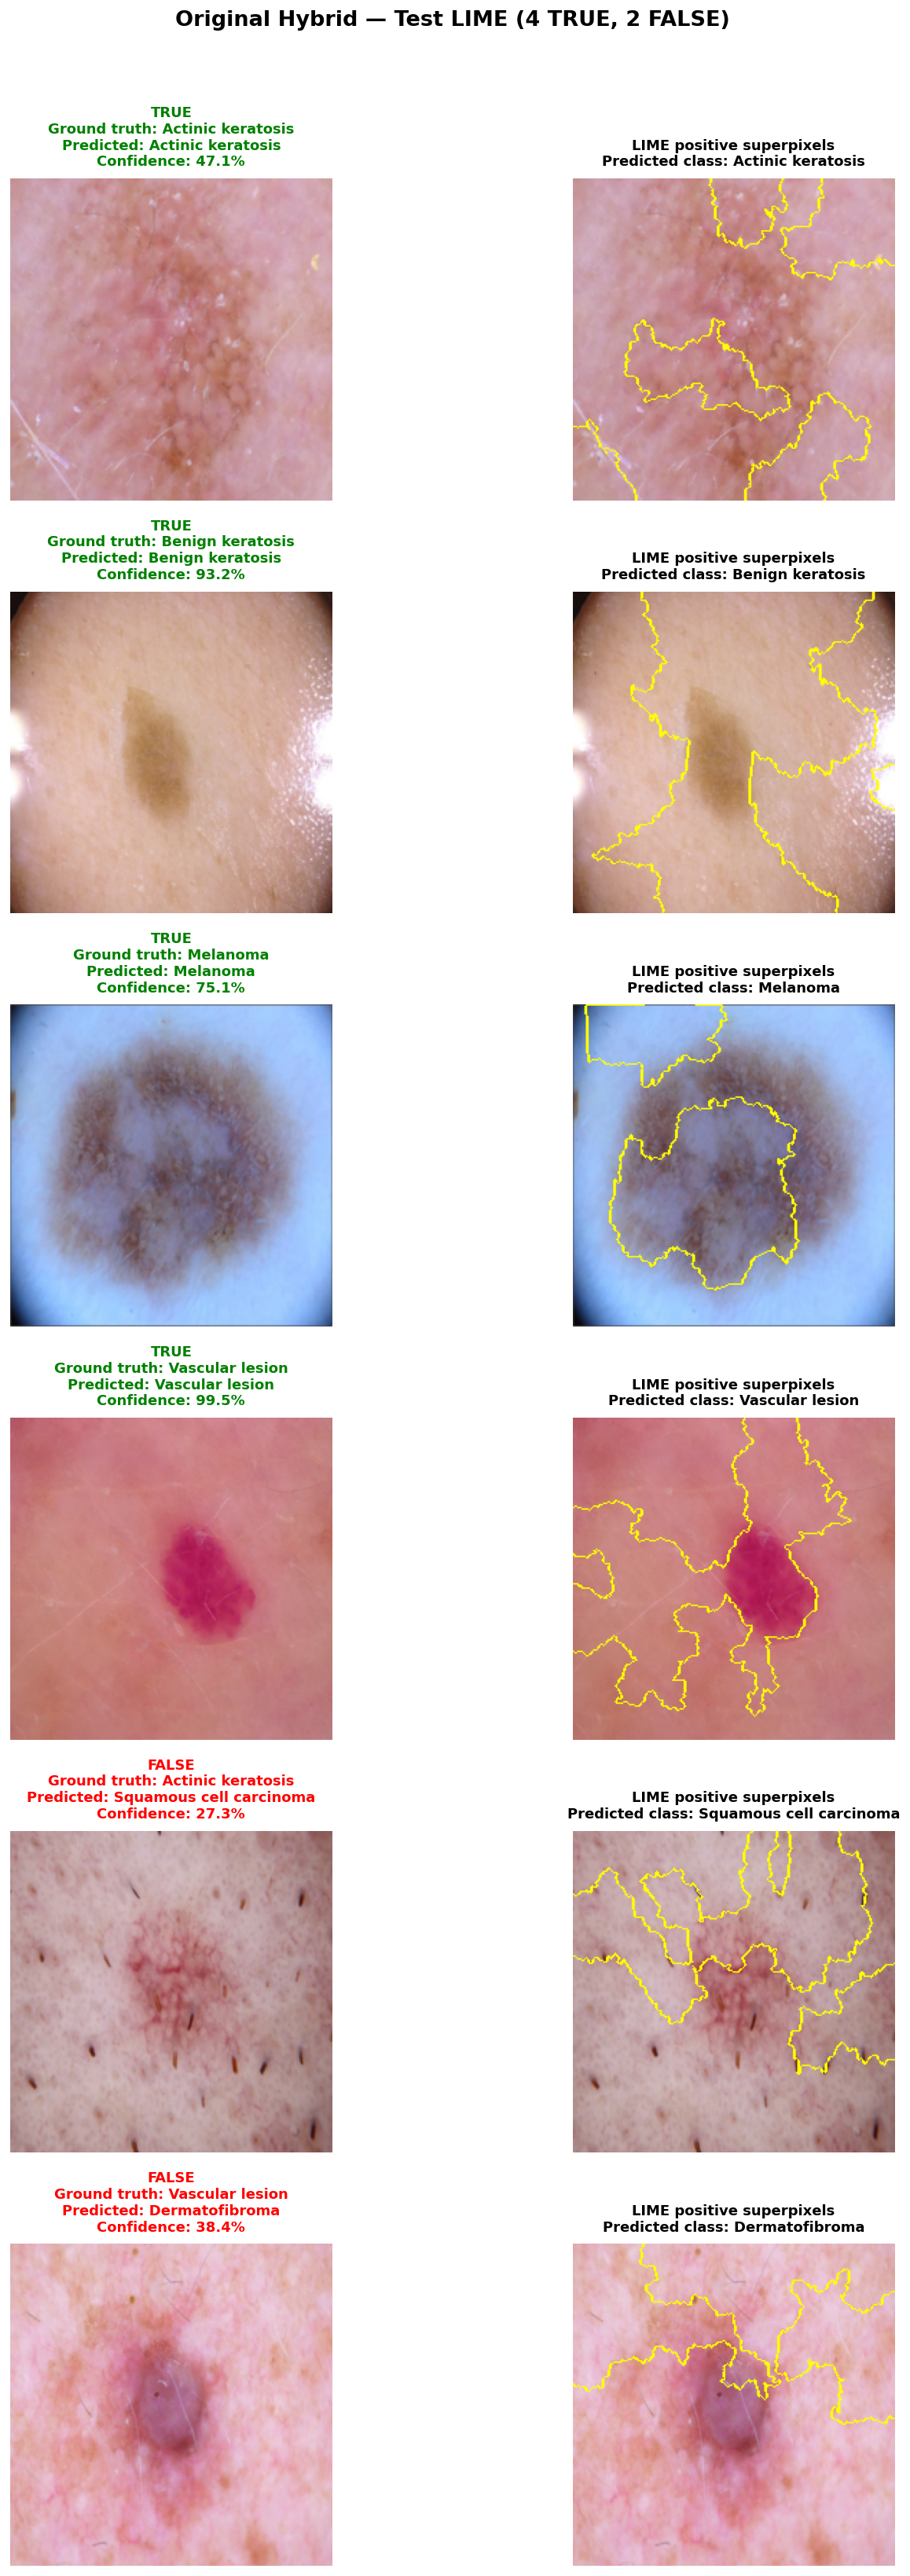

Saved: /kaggle/working/hybrid_skin_results/explainability_4_models/original_hybrid_test_lime_4true_2false.png

Generating LIME for: Weighted Hybrid
Correct predictions available: 97
Incorrect predictions available: 29
Selected 4 TRUE and 2 FALSE samples.


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

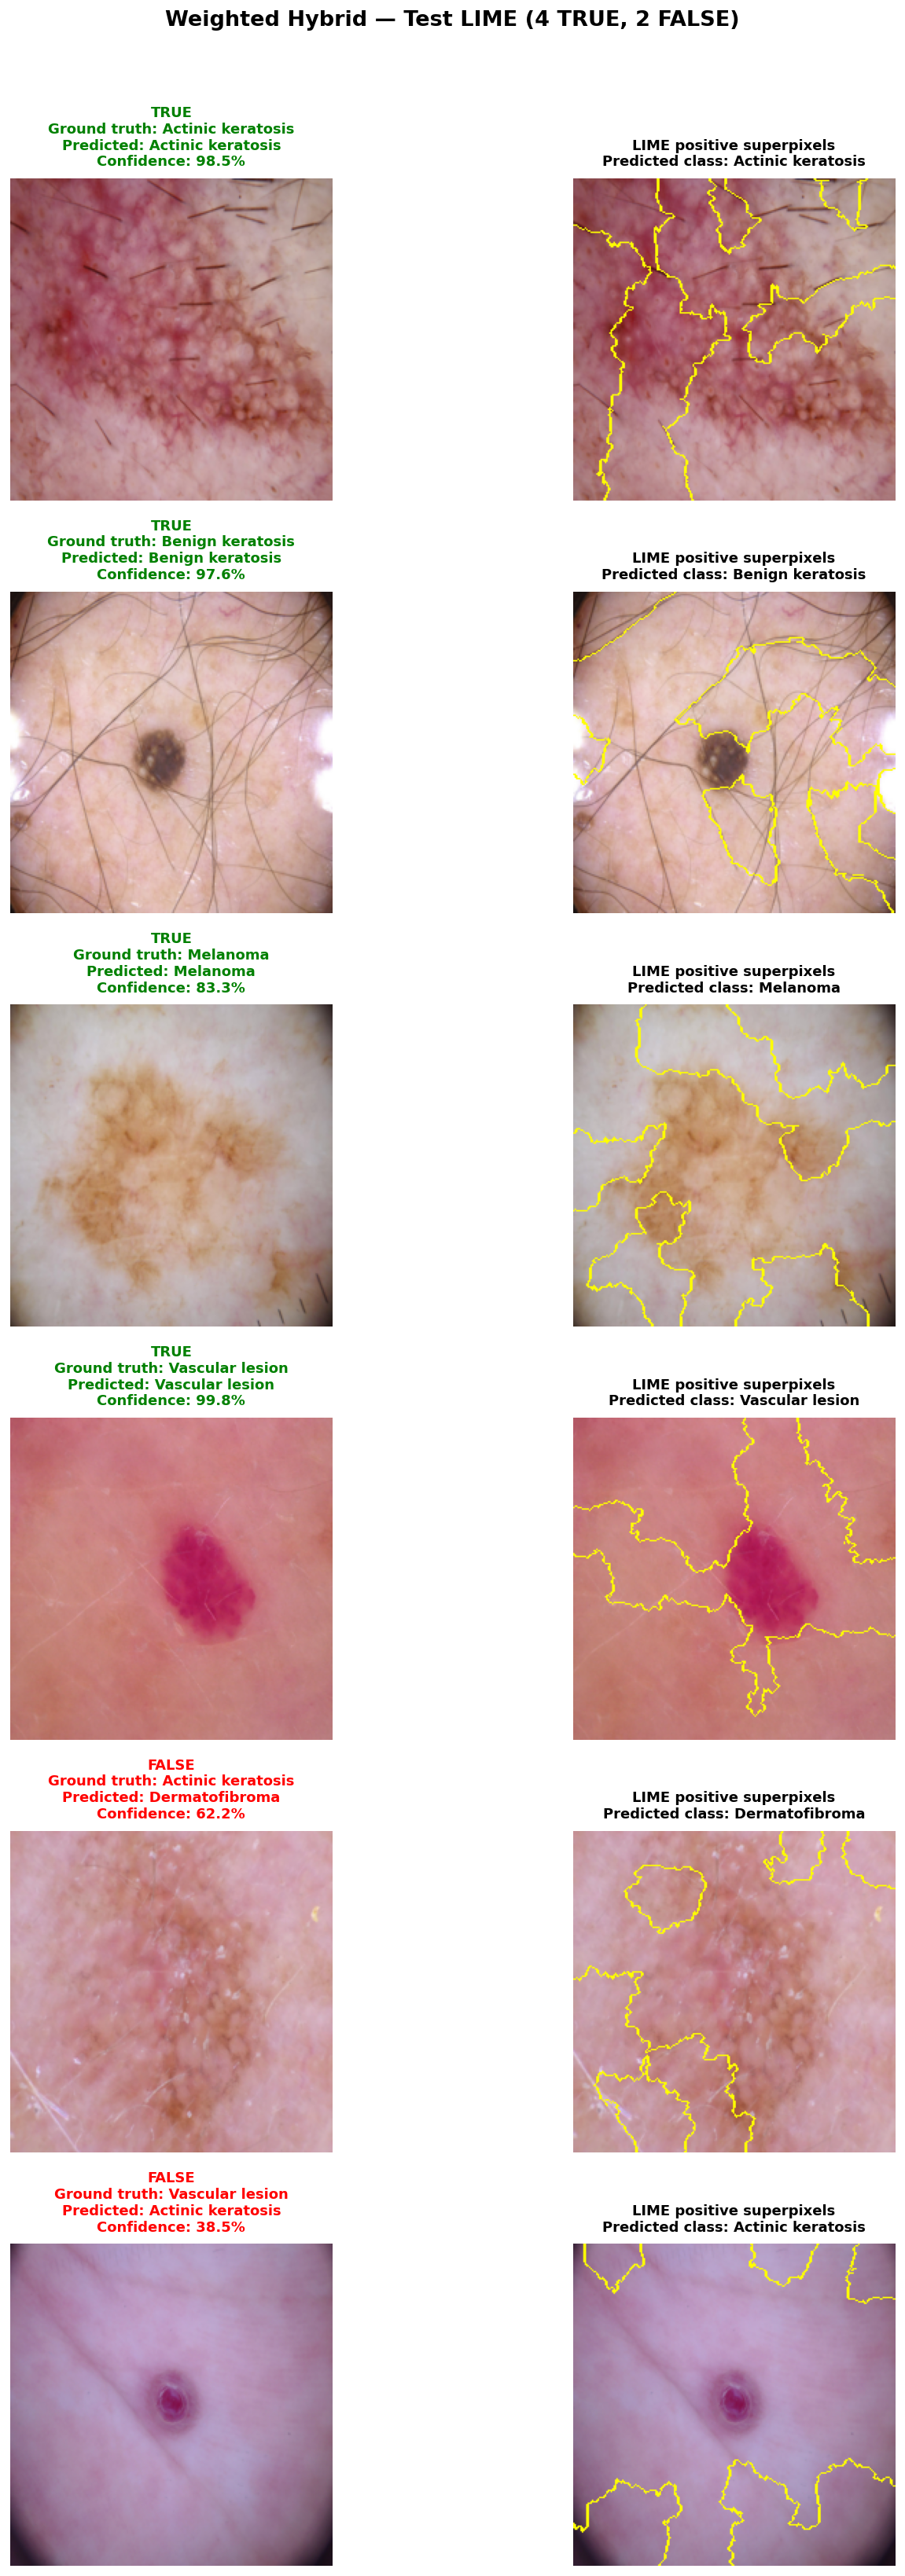

Saved: /kaggle/working/hybrid_skin_results/explainability_4_models/weighted_hybrid_test_lime_4true_2false.png

Generating LIME for: EfficientNet-B0
Correct predictions available: 84
Incorrect predictions available: 42
Selected 4 TRUE and 2 FALSE samples.


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

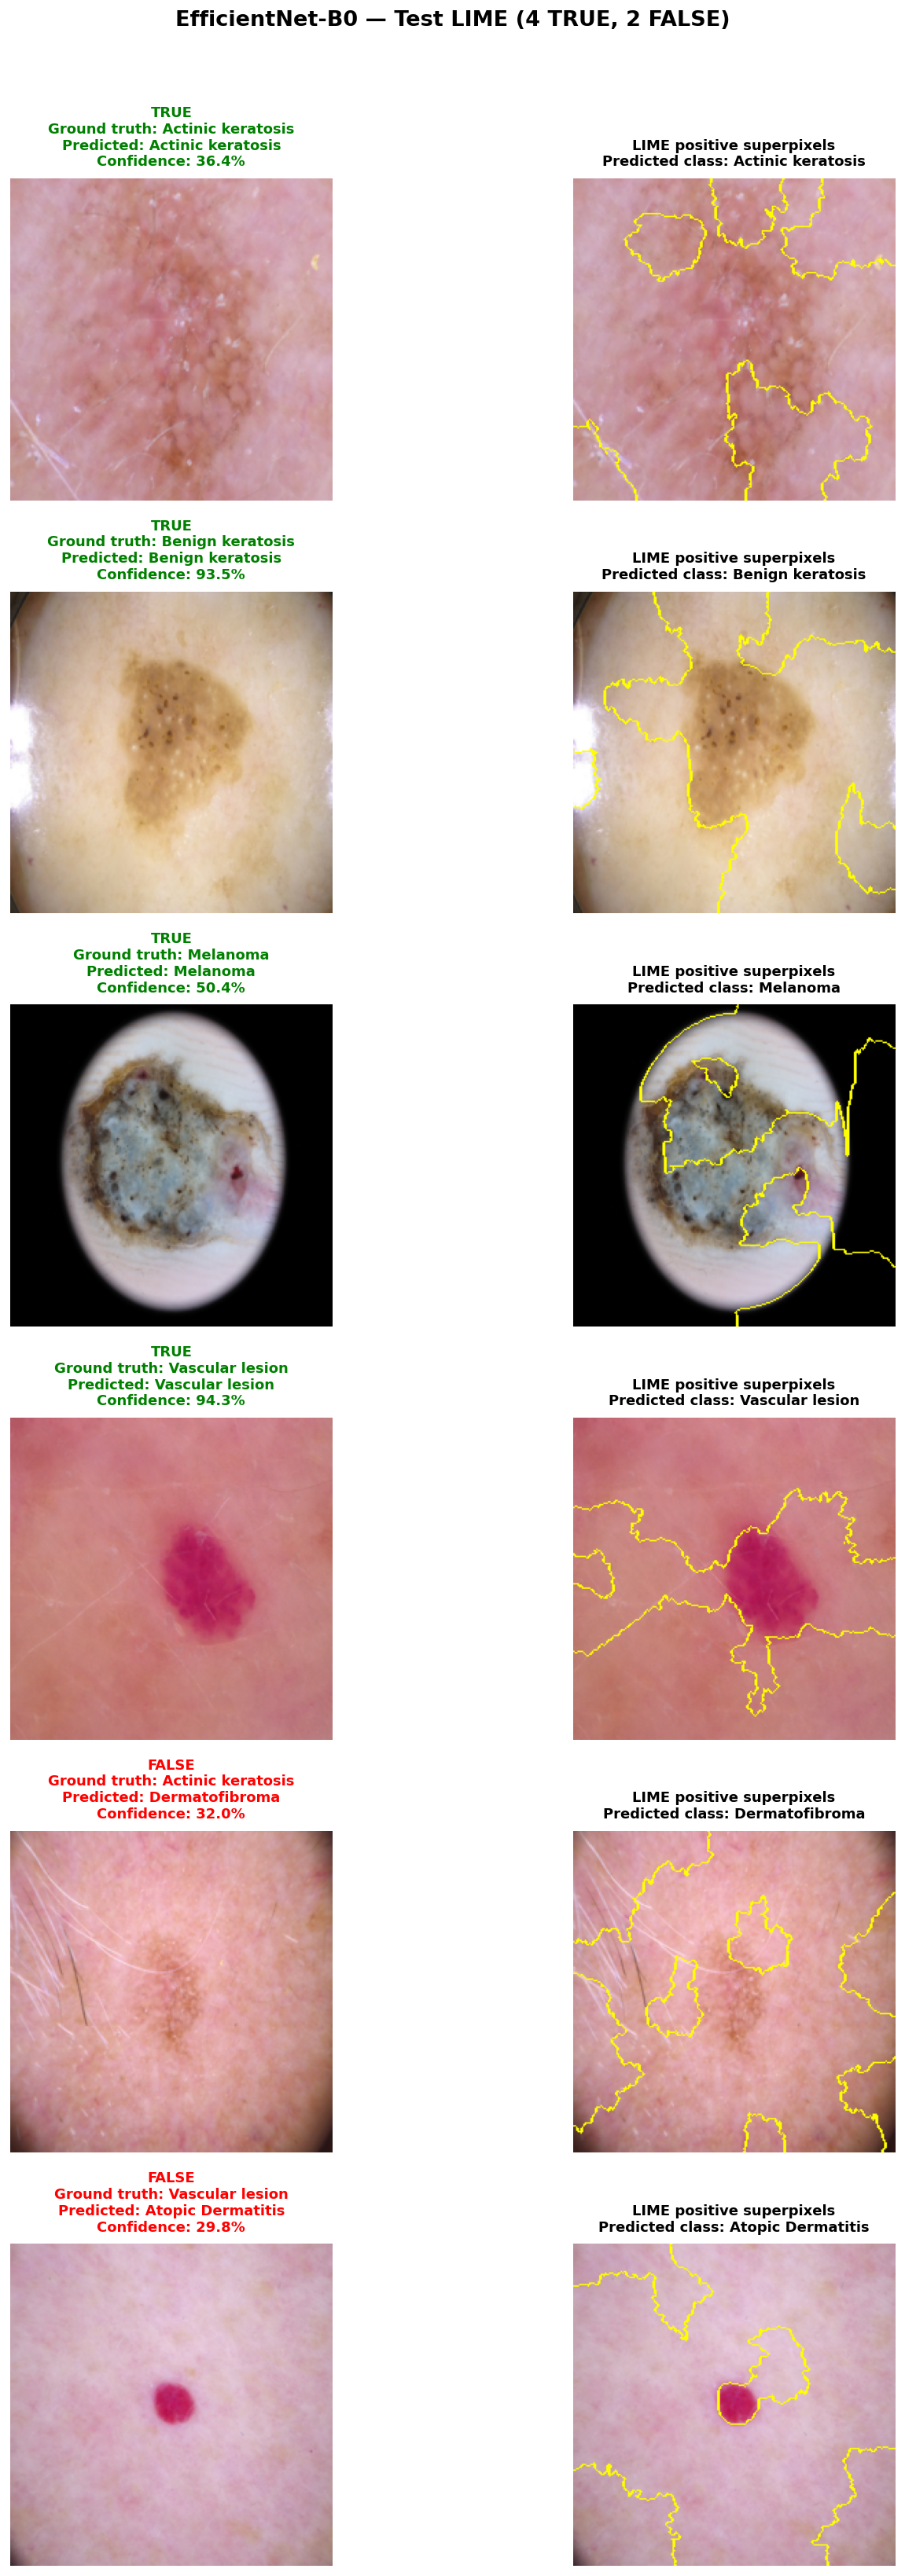

Saved: /kaggle/working/hybrid_skin_results/explainability_4_models/efficientnet_b0_test_lime_4true_2false.png

Generating LIME for: ResNet50
Correct predictions available: 101
Incorrect predictions available: 25
Selected 4 TRUE and 2 FALSE samples.


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

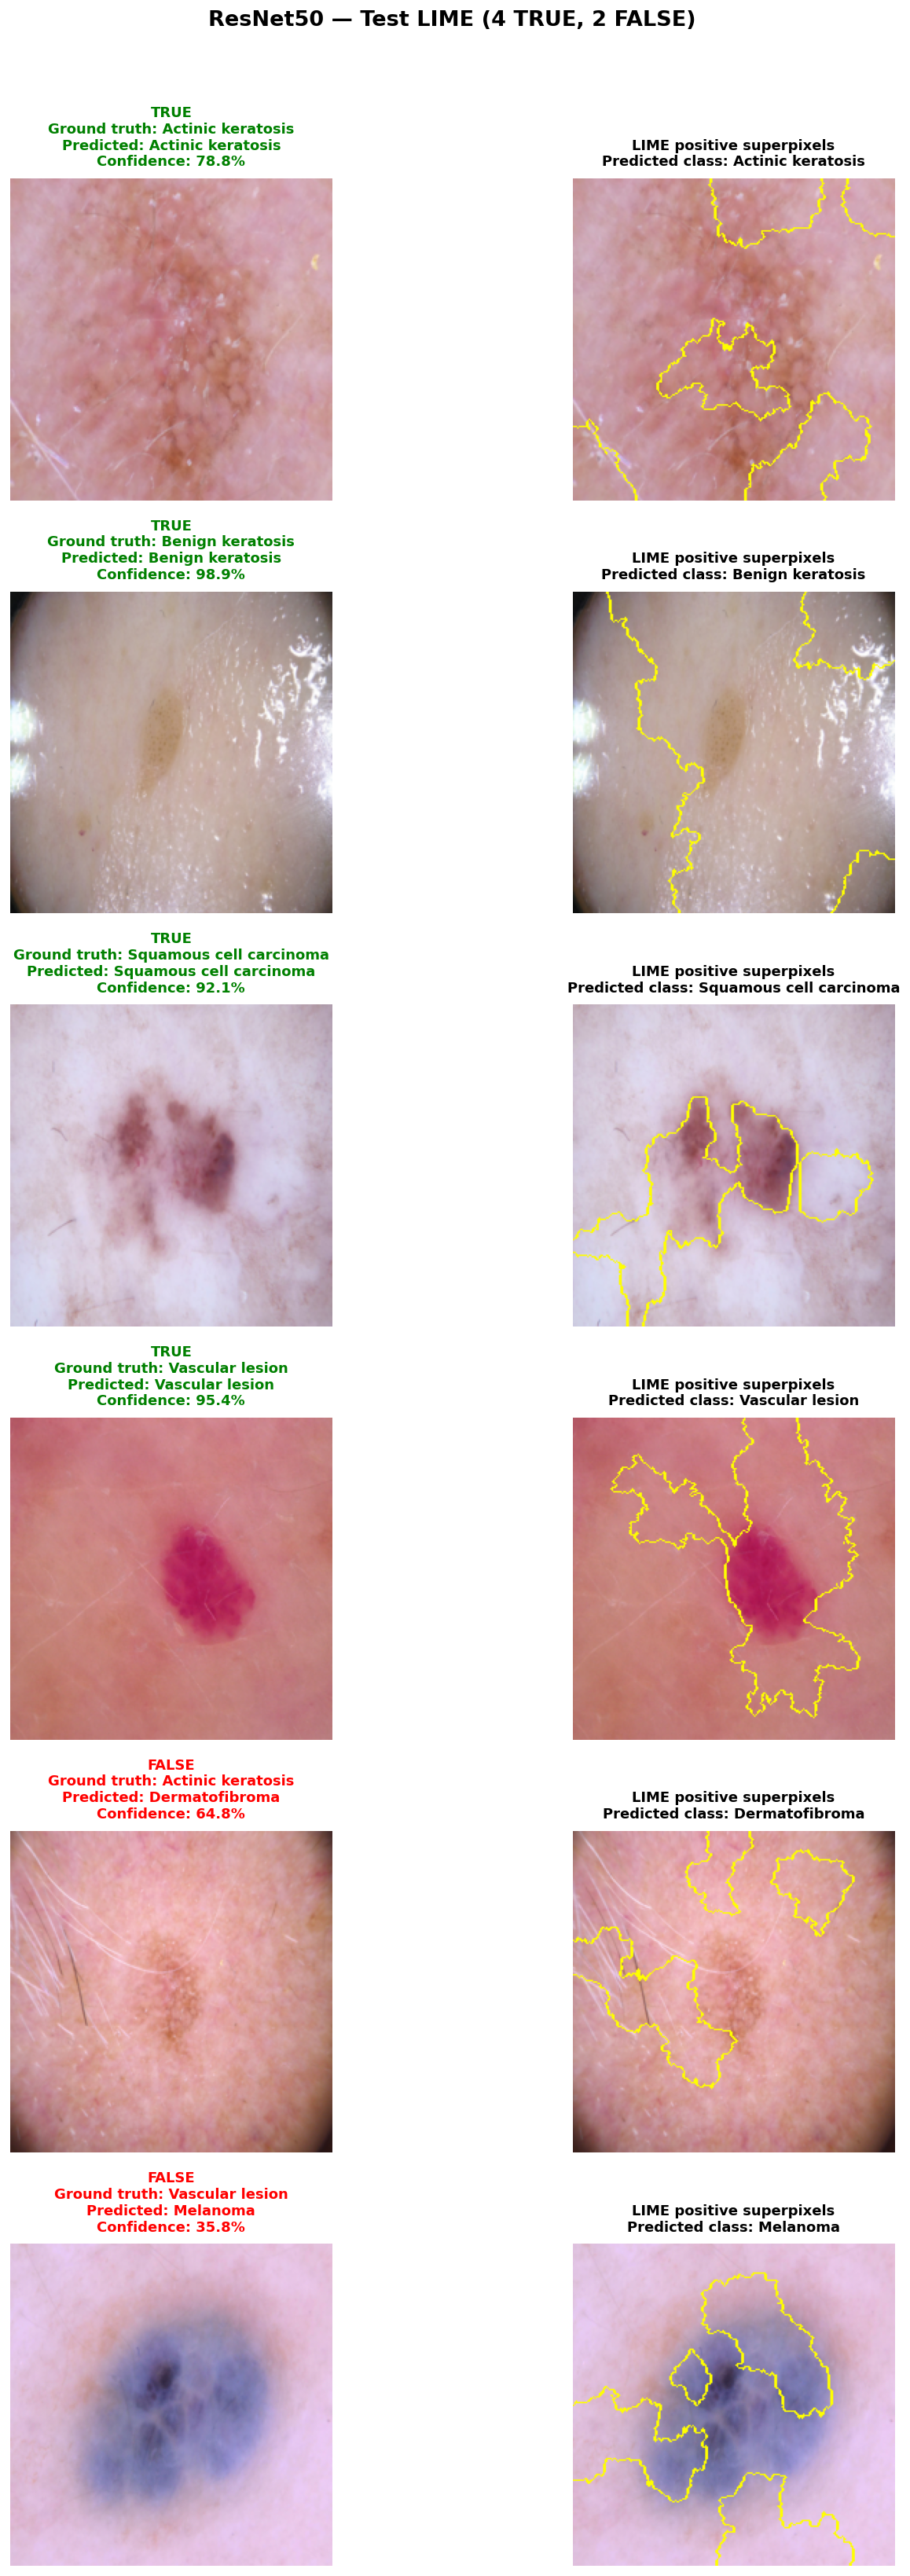

Saved: /kaggle/working/hybrid_skin_results/explainability_4_models/resnet50_test_lime_4true_2false.png

Selection summary:


Status,FALSE,TRUE
Model,,
EfficientNet-B0,2,4
Original Hybrid,2,4
ResNet50,2,4
Weighted Hybrid,2,4



Sample details saved: /kaggle/working/hybrid_skin_results/explainability_4_models/test_lime_selected_samples.csv
CELL 30 COMPLETED


In [47]:

# ============================================================
# CELL 30: LIME FOR ALL 4 MODELS
# 6 samples per model: 4 TRUE + 2 FALSE
# ============================================================

import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from lime import lime_image
from skimage.segmentation import mark_boundaries

TRUE_SAMPLES = 4
FALSE_SAMPLES = 2
TOTAL_SAMPLES = TRUE_SAMPLES + FALSE_SAMPLES

lime_explainer = lime_image.LimeImageExplainer(
    random_state=SEED
)

lime_selection_records = []

for spec in MODEL_SPECS:

    model_name = spec["name"]
    model_obj = spec["model_obj"]
    checkpoint_path = spec["checkpoint"]

    print(f"\nGenerating LIME for: {model_name}")

    load_checkpoint_into_model(
        model_obj,
        checkpoint_path
    )

    predict_fn = make_lime_predict_fn(model_obj)

    # --------------------------------------------------------
    # 1. Find correct and incorrect predictions
    # --------------------------------------------------------
    correct_samples = []
    incorrect_samples = []

    for idx in range(len(analysis_dataset)):

        tensor_img, true_idx = analysis_dataset[idx]

        pred_idx, confidence, probs = predict_single_tensor(
            model_obj,
            tensor_img
        )

        record = {
            "idx": idx,
            "tensor_img": tensor_img,
            "true_idx": int(true_idx),
            "pred_idx": int(pred_idx),
            "confidence": float(confidence)
        }

        if pred_idx == int(true_idx):
            correct_samples.append(record)
        else:
            incorrect_samples.append(record)

    print("Correct predictions available:", len(correct_samples))
    print("Incorrect predictions available:", len(incorrect_samples))

    # Deterministic selection: evenly spaced across available samples
    def select_evenly(records, count):
        if len(records) <= count:
            return records

        positions = np.linspace(
            0,
            len(records) - 1,
            count,
            dtype=int
        )

        return [records[p] for p in positions]

    selected_true = select_evenly(
        correct_samples,
        TRUE_SAMPLES
    )

    selected_false = select_evenly(
        incorrect_samples,
        FALSE_SAMPLES
    )

    selected_samples = selected_true + selected_false

    # TRUE first, then FALSE
    print(
        f"Selected {len(selected_true)} TRUE and "
        f"{len(selected_false)} FALSE samples."
    )

    if len(selected_true) < TRUE_SAMPLES:
        print(
            f"WARNING: Requested {TRUE_SAMPLES} TRUE samples, "
            f"but only {len(selected_true)} are available."
        )

    if len(selected_false) < FALSE_SAMPLES:
        print(
            f"WARNING: Requested {FALSE_SAMPLES} FALSE samples, "
            f"but only {len(selected_false)} are available."
        )

    # --------------------------------------------------------
    # 2. Plot selected samples
    # --------------------------------------------------------
    n = len(selected_samples)

    if n == 0:
        print("No samples available; skipping this model.")
        continue

    fig, axes = plt.subplots(
        n,
        2,
        figsize=(13, 4.2 * n),
        dpi=130,
        squeeze=False
    )

    for row, item in enumerate(selected_samples):

        idx = item["idx"]
        tensor_img = item["tensor_img"]
        true_idx = item["true_idx"]
        pred_idx = item["pred_idx"]
        confidence = item["confidence"]

        rgb = tensor_to_rgb_numpy(tensor_img)

        correct = pred_idx == true_idx
        status = "TRUE" if correct else "FALSE"
        status_color = "green" if correct else "red"

        # Original image
        axes[row, 0].imshow(rgb)
        axes[row, 0].set_title(
            f"{status}\n"
            f"Ground truth: {class_names[true_idx]}\n"
            f"Predicted: {class_names[pred_idx]}\n"
            f"Confidence: {confidence * 100:.1f}%",
            fontsize=10,
            fontweight="bold",
            color=status_color,
            pad=9
        )
        axes[row, 0].axis("off")

        # LIME explanation for the predicted class
        explanation = lime_explainer.explain_instance(
            rgb,
            classifier_fn=predict_fn,
            labels=(pred_idx,),
            hide_color=0,
            num_samples=LIME_NUM_SAMPLES,
            batch_size=16
        )

        lime_img, lime_mask = explanation.get_image_and_mask(
            label=pred_idx,
            positive_only=True,
            num_features=8,
            hide_rest=False
        )

        lime_boundary = mark_boundaries(
            lime_img,
            lime_mask
        )

        axes[row, 1].imshow(lime_boundary)
        axes[row, 1].set_title(
            f"LIME positive superpixels\n"
            f"Predicted class: {class_names[pred_idx]}",
            fontsize=10,
            fontweight="bold",
            pad=9
        )
        axes[row, 1].axis("off")

        lime_selection_records.append({
            "Model": model_name,
            "Split": ANALYSIS_SPLIT,
            "Dataset index": idx,
            "Ground truth": class_names[true_idx],
            "Prediction": class_names[pred_idx],
            "Confidence (%)": round(confidence * 100, 2),
            "Status": status
        })

    fig.suptitle(
        f"{model_name} — {ANALYSIS_SPLIT} LIME "
        f"({len(selected_true)} TRUE, {len(selected_false)} FALSE)",
        fontsize=15,
        fontweight="bold",
        y=1.0
    )

    plt.tight_layout(rect=[0, 0, 1, 0.985])

    save_path = (
        EXPLAIN_DIR
        / f"{safe_name(model_name)}_{ANALYSIS_SPLIT.lower()}_lime_4true_2false.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", save_path)

# Save selected sample metadata
selection_df = pd.DataFrame(lime_selection_records)

selection_csv = (
    EXPLAIN_DIR
    / f"{ANALYSIS_SPLIT.lower()}_lime_selected_samples.csv"
)

selection_df.to_csv(selection_csv, index=False)

print("\nSelection summary:")
if not selection_df.empty:
    display(
        selection_df.groupby(["Model", "Status"])
        .size()
        .unstack(fill_value=0)
    )

print("\nSample details saved:", selection_csv)
print("CELL 30 COMPLETED")
